[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kulinskij-tech/ClassMech/blob/main/ClassMech_Python/classmech_oscphdiag.ipynb)


In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display


def animate_parameter(draw,minimum,maximum,value,step,label):
    draw(value)
    slider=widgets.FloatSlider(value=value,min=minimum,max=maximum,step=step,
                               description=label,continuous_update=False)
    play=widgets.Play(value=0,min=0,max=int(round((maximum-minimum)/step)),step=1,interval=120,repeat=False)
    def advance(change):
        slider.value=min(maximum,minimum+change['new']*step)
    play.observe(advance,names='value')
    view=widgets.interactive_output(lambda parameter: draw(parameter),{'parameter':slider})
    display(widgets.VBox([widgets.HBox([play,slider]),view]))
    return slider,play,view

import base64
from IPython.display import Audio,Image

# Complex numbers and the impedance method for problems on harmonic oscillations

## Introduction. Complex numbers

Periodic motion is a basic physical model, alongside uniform and uniformly accelerated motion. A variable $X$ is periodic if $X\left(t+T\right)=X\left(t\right)$; the smallest positive such interval, when it exists, is its period $T$. In mechanics, $X$ often describes position.

Let us consider a uniform motion along a circle with a cyclic frequency ω. It is periodic in the position of the particle. Let’s write the equation of the trajectory in the coordinate system with the origin at the center of the circle:

$$
{x}^{2}+{y}^{2}=R \Rightarrow \left\{\begin{matrix}x\left(t\right) = R \cos{\left(\omega  t +\alpha \right)}\\ y\left(t\right) = R \sin{\left(\omega  t +\alpha \right)}\end{matrix}\right.
$$

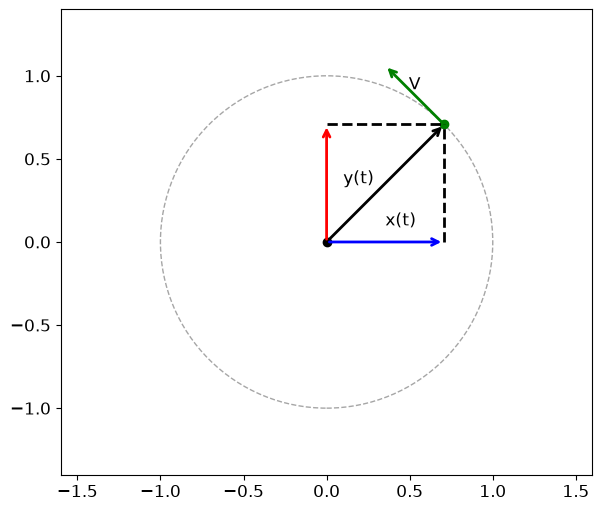

In [2]:
plt.rcParams.update({'font.size':12,'lines.linewidth':2})
def re(z): return sp.simplify(sp.re(sp.expand_complex(z)))
def im(z): return sp.simplify(sp.im(sp.expand_complex(z)))
def abscmplx(z): return sp.sqrt(re(z)**2+im(z)**2)
def rcirc(t): return np.array([np.cos(t),np.sin(t)])
def arrow(ax,start,end,color='black'):
    ax.annotate('',xy=end,xytext=start,arrowprops={'arrowstyle':'->','color':color,'lw':2})
def show_circle(time,forces=False):
    point=rcirc(time); velocity=np.array([-np.sin(time),np.cos(time)])
    fig,ax=plt.subplots(figsize=(6,5),layout='constrained'); ax.add_patch(plt.Circle((0,0),1,fill=False,ls='--',color='.65'))
    arrow(ax,[0,0],point); ax.plot(0,0,'ko'); ax.plot(*point,'o',color='green'); arrow(ax,point,point+.5*velocity,'green')
    ax.plot([point[0],point[0]],[0,point[1]],'k--')
    if forces:
        arrow(ax,[point[0],0],[0,0],'blue'); arrow(ax,[point[0],0],[point[0]+velocity[0],0],'green')
        arrow(ax,point,point+.5*np.array([1,-1])*velocity,'gray')
        ax.text(point[0],-.15,'X(t)'); ax.text(point[0]+velocity[0],-.15,r'$V_x(t)$',color='green')
        ax.text(0,.1,'F(t)',color='blue'); ax.text(*(point+.35*velocity),r'$V$'); ax.text(*(point+.35*np.array([1,-1])*velocity),r'$V^*$')
    else:
        arrow(ax,[0,0],[point[0],0],'blue'); arrow(ax,[0,0],[0,point[1]],'red'); ax.plot([0,point[0]],[point[1],point[1]],'k--')
        ax.text(point[0]/2,.1,'x(t)'); ax.text(.1,point[1]/2,'y(t)'); ax.text(*(point+.3*velocity),'V')
    ax.set(xlim=(-1.6,1.6),ylim=(-1.4,1.4),aspect='equal'); plt.show()
circle_controls=animate_parameter(show_circle,0,8*np.pi,np.pi/4,.08,'Time')

Projections of particle velocity have the form:

$$
{v}_{x}\left(t\right) =-\omega  y\left(t\right)= - \omega  R \sin{\left(\omega  t +\alpha \right)}, {v}_{y}\left(t\right)=\omega  x\left(t\right) = \omega  R \cos{\left(\omega  t +\alpha \right)}
$$

These relations also follow from the geometry of circular motion: $\mathbf r\cdot\mathbf v=0$, so the distance from the centre is constant. Projection onto the x axis gives harmonic oscillation:

$$
{E}_{x} = \frac{m {\omega }^{2}{x}^{2}}{2}+\frac{m {v}_{x}^{2}}{2}=\frac{m {\omega }^{2}{R}^{2}}{2}
$$

If you remember that ${\omega }^{2}=k/m$ , then we come exactly to the model of the harmonic oscillator (a material point moving under the influence of Hooke’s force).

Thus, any one-dimensional harmonic process (oscillations) according to any physical parameter X can be considered as a projection of uniform motion along a circle, occurring on the (X,Y) plane. Coordinate Y plays the role of fictitious, auxiliary in order to visually present the state X of the real system as a projection of the auxiliary state (X,Y). The rate of change of such a state is related to this vector as:

$$
{V}_{X}=-\omega  Y, {V}_{Y}=\omega  X
$$

From geometry it is clear that the direction of the velocity vector differs from the direction of the radius vector by π/2.

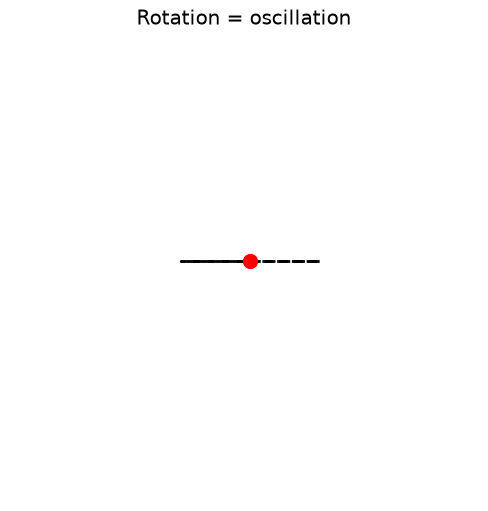

In [3]:
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
def show_rotation_projection(time):
    q=np.linspace(0,2*np.pi,300)
    fig=plt.figure(figsize=(6,5),layout='constrained'); ax=fig.add_subplot(projection='3d')
    ax.plot(np.cos(q),np.sin(q),np.zeros_like(q),'k--'); ax.scatter(0,0,0,color='black')
    ax.add_collection3d(Poly3DCollection([[[-1.8,-1.8,0],[-1.8,1.8,0],[1.8,1.8,0],[1.8,-1.8,0]]],facecolor='green',alpha=.15))
    ax.scatter(np.cos(time),np.sin(time),0,s=100,color='red')
    viewpoint=np.array([2*np.cos(time/8)**2,np.sin(time/8)**2,0 if time<2*np.pi else np.sin(time/2)**4])
    ax.view_init(elev=np.degrees(np.arctan2(viewpoint[2],np.linalg.norm(viewpoint[:2]))),azim=np.degrees(np.arctan2(viewpoint[1],viewpoint[0])))
    ax.set(xlim=(-2,2),ylim=(-2,2),zlim=(-2,2),title='Rotation = oscillation'); ax.set_box_aspect((1,1,1)); ax.axis('off'); plt.show()
projection_controls=animate_parameter(show_rotation_projection,0,8*np.pi,0,.08,'Time')

Introduce the plane vector $Z=\left(X,Y\right)$. Its derivative is $\dot Z=\omega\left(-Y,X\right)$: a rotation by $\pi/2$, followed by multiplication by $\omega$. The physical displacement can be recovered from the first coordinate. This geometric representation is the basis of the phasor method.

$$
\text{speed of } \dot{Z}=\text{acceleration} = -{\omega }^{2}Z
$$

Differentiating again gives the familiar centripetal acceleration. Position, velocity, and acceleration retain fixed phase differences, which lets us compare their amplitudes without following the rotation in time.

In addition, since the position of the body during harmonic oscillation of a given amplitude is uniquely determined by the phase (angle), we find that along with Cartesian coordinates on the (X,Y) plane, it is convenient to use polar coordinates:

$$
\rho  =\sqrt{{X}^{2}+{Y}^{2}}, \sin{\varphi}  =Y/\rho , \cos{\varphi}  =X/\rho
$$

Write $Z=\rho\left(\cos{\varphi},\sin{\varphi}\right)$, where $\rho=\left|Z\right|$ is the modulus and $\varphi=\arg Z$ is the argument. Multiplication can be defined on these plane vectors as follows:

$$
{Z}_{1}{Z}_{2}={\rho }_{1}{\rho }_{2} \left(\cos{\left({\varphi }_{1}+{\varphi }_{2}\right)},\sin{\left({\varphi }_{1}+{\varphi }_{2}\right)}\right)={Z}_{2}{Z}_{1}
$$

Besides

$$
{Z}_{1}\left({Z}_{2}{Z}_{3}\right)=\left({Z}_{1}{Z}_{2}\right){Z}_{3} ,  {Z}_{1}\left({Z}_{2}+{Z}_{3}\right)={Z}_{1}{Z}_{2}+{Z}_{1}{Z}_{3},
$$

Going back to Cartesian coordinates using trigonometric cosine/sine sum formulas, we get:

$$
{Z}_{1}{Z}_{2}=\left({X}_{1},{Y}_{1}\right)\left({X}_{2},{Y}_{2}\right) = \left({X}_{1}{X}_{2}-{Y}_{1}{Y}_{2},{X}_{1}{Y}_{2}+{Y}_{1}{X}_{2}\right)
$$

It is clear that such multiplication in the case of vectors of the form (X,0) is simply the multiplication of numbers, and multiplication by the vector (0,1) is equivalent to rotation by π/2. Correspondingly

$$
\left(0,1\right)\left(0,1\right)=\left(-1,0\right), \left(0,1\right)\to i, {i}^{2}=-1, i=\sqrt{-1}
$$

The projections X,Y are called the real and imaginary parts of the complex number Z:

$$
X = Re Z, Y = Im Z
$$

A set of pairs of real numbers equipped with such multiplication is called a set of complex numbers (more precisely, a field in the terminology of abstract algebra), because the addition and multiplication of such pairs satisfies the same laws as analogous operations for real numbers. For brevity, just write

$$
Z = \left(X,Y\right) = X+i Y,
$$

the complex number

$$
{Z}^{*} = \left(X,-Y\right) = X-i Y,
$$

is called complex conjugate of $Z$ and:

$$
X = Re Z = \frac{Z+{Z}^{*}}{2}, Y = Im Z=\frac{Z-{Z}^{*}}{2i}
$$

It is clear that ${Z}^{*}Z = \left|Z\right|^{2}$ 

$$
{X}^{2}+{Y}^{2}=\left(X+i Y\right)\left(X-i Y\right)
$$

Complex numbers therefore give roots to every quadratic equation and provide an algebraic language for trigonometric relations. In particular,

$$
{Z}_{1}^{*}{Z}_{2}=\left({X}_{1}-i {Y}_{1}\right)\left({X}_{2}+i {Y}_{2}\right)={X}_{1}{X}_{2}+{Y}_{1}{Y}_{2}+i\left({X}_{1}{Y}_{2}-{X}_{2}{Y}_{1}\right)={\vec{Z}}_{1}\cdot {\vec{Z}}_{2}+i {\vec{Z}}_{1}\times {\vec{Z}}_{2}
$$

$$
Re \left({Z}_{1}^{*}{Z}_{2}\right) = {\vec{Z}}_{1}\cdot {\vec{Z}}_{2}, Im \left({Z}_{1}^{*}{Z}_{2}\right)={\vec{Z}}_{1}\times {\vec{Z}}_{2}
$$

where in the last equality ${Z}_{1,2}$ are treated as ordinary plane vectors.

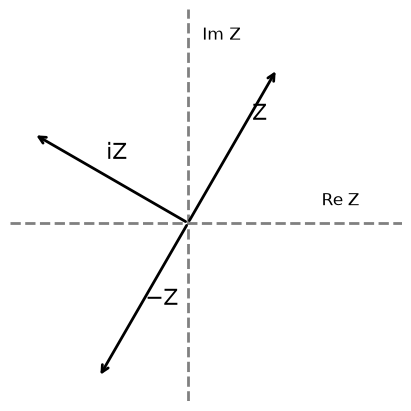

In [4]:
def show_complex_vectors():
    z=np.array([.5,np.sqrt(3)/2]); iz=np.array([-z[1],z[0]])
    fig,ax=plt.subplots(figsize=(4,4),layout='constrained')
    for vector,label in [(z,'Z'),(-z,'−Z'),(iz,'iZ')]:
        arrow(ax,[0,0],vector); ax.text(*(vector*.6+.06),label,fontsize=16)
    ax.axhline(0,color='gray',ls='--'); ax.axvline(0,color='gray',ls='--')
    ax.text(.75,.1,'Re Z'); ax.text(.08,1.03,'Im Z'); ax.set(xlim=(-1,1.2),ylim=(-1,1.2),aspect='equal'); ax.axis('off'); plt.show()
show_complex_vectors()

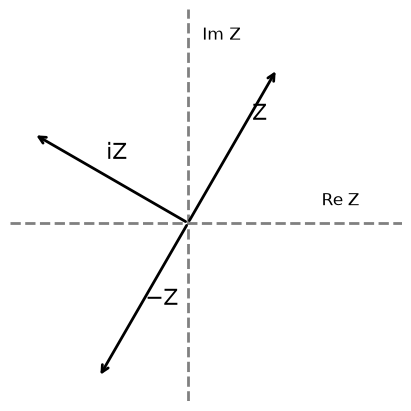

In [5]:
# This source input is a saved copy of the previous graphic.
show_complex_vectors()

Harmonic quantity, its speed and acceleration in the complex representation when ω = 1.

If we enter the angle function:

$$
f\left(\varphi \right) = \cos{\varphi}  +i \sin{\varphi}
$$

then it has the well-known property of the exponential function:

$$
f\left({\varphi }_{1}+{\varphi }_{2}\right)= f\left({\varphi }_{1}\right)f\left({\varphi }_{2}\right) \Leftrightarrow  {a}^{{x}_{1}}{a}^{{x}_{2}}={a}^{{x}_{1}+{x}_{2}}
$$

If you use the basic rule for the speed of changing the function, then

$$
f'\left(\omega  t\right) =i \omega  f\left(\omega  t\right),
$$

which means

$$
f\left(\varphi \right)=exp\left(i \varphi \right)
$$

Thus

$$
exp\left(i \varphi \right) = \cos{\varphi}  +i \sin{\varphi}
$$

and correspondingly

$$
\cos{\varphi}  = \frac{exp\left(i \varphi \right)+exp\left(-i \varphi \right)}{2}, \sin{\varphi}  = \frac{exp\left(i \varphi \right)-exp\left(-i \varphi \right)}{2i}
$$

These formulas are called Euler’s formulas.

Obviously:

$$
1=\left|exp\left(i \varphi \right)\right|^{2} = \cos^{2}{\varphi}  +\sin^{2}{\varphi}
$$

For some standard angles, for example, we get:

$$
exp\left(i \frac{\pi }{2}\right)=i , exp\left(i 2 \pi \right)=1, exp\left(i  \pi \right)=-1 , exp\left(i \frac{\pi }{4}\right)=\frac{1+i}{\sqrt{2}}, exp\left(i \frac{\pi }{3}\right)=\frac{1+i\sqrt{3}}{2}
$$

Also from here you can easily get reduction formulas

$$
exp\left(i \left(\varphi +\frac{\pi }{2}\right)\right)=\cos{\left(\varphi +\frac{\pi }{2}\right)}+i \sin{\left(\varphi +\frac{\pi }{2}\right)} = i\left(\cos{\varphi}  +i \sin{\varphi} \right)=-\sin{\varphi} +i \cos{\varphi}  \Rightarrow \cos{\left(\varphi +\frac{\pi }{2}\right)}=-\sin{\varphi} , \sin{\left(\varphi +\frac{\pi }{2}\right)}=\cos{\varphi}
$$

etc. Operation with complex numbers makes it possible to solve many “real” problems in which trigonometric functions are encountered.

Example: Find the sum of a series $\sin{x}+\sin{2x}+\sin{3x}+...+\sin{n x}=?$ Hint: use Euler’s formula

Using a complex representation, the radius vector of a particle on a circle can be written as:

$$
Z\left(t\right) = \left|Z\right| exp\left(i \omega  t+i {\varphi }_{0}\right) = {Z}_{\omega }exp\left(i \omega  t\right), {Z}_{\omega }=\left|Z\right|{e}^{i {\varphi }_{0}}
$$

The language of complex numbers introduced above allows one to describe oscillatory processes in a single way. Let’s formulate the basic rule

### Basic rule of amplitudes

The quantity Z(t), which changes according to the harmonic law with the frequency ω, is matched with its frequency image ${Z}_{\omega }$ - the Fourier amplitude at the given frequency - a complex number (vector on the plane). This value does not depend on time. The rate of change Z(t), i.e. derivative $\frac{d Z}{d t}$ has a Fourier amplitude

$$
{\left(\frac{d Z}{d t}\right)}_{\omega }=i \omega  {Z}_{\omega }
$$

Thus differentiation rotates the complex amplitude by a quarter-turn and scales it by the angular frequency.

## Harmonic oscillator

Let’s apply the method of complex numbers to the simplest harmonic oscillatory system - a linear oscillator. Its mechanical realization is a material point on a spring. Equation of motion (Newton’s second law)

$$
m a =-k x
$$

as is known (remember that the acceleration of the sine/cosine change is “minus sine/cosine”) defines oscillations with the frequency $\omega =\sqrt{k/m}$ . A non-mechanical example of an oscillator is electromagnetic vibrations/waves, sound (elastic vibrations of continuous media). In general, harmonic oscillations occur whenever small deviations from the stable equilibrium position are considered, when the restoring force can be considered approximately linear from the displacement. Since a = (d^2 x)/(d t^2), from the basic rule of amplitudes it follows that:

$$
{a}_{\omega }=i \omega  {v}_{\omega }=-{\omega }^{2}{x}_{\omega } = -\frac{k}{m}{x}_{\omega }\Rightarrow \left({\omega }^{2}-\frac{k}{m}\right){x}_{\omega }=0\Rightarrow {\omega }_{0}=\sqrt{\frac{k}{m}}
$$

Since the oscillations occur under the action of the elastic force, the rate of change of the kinetic energy is equal to the instantaneous power of this force:

$$
\frac{d {E}_{\text{kin}}}{d t}=m v \frac{d v}{d t}=-k x v = -m {\omega }_{0}^{2}x v
$$

Due to the periodicity of the movement, it is reasonable to determine the average power value for the period. It is clear that in this case this value is equal to 0 (since energy is conserved). Let’s see how it turns out from the complex form:

$$
\frac{d {E}_{\text{kin}}}{d t}=F v = Re \left(F {e}^{i {\omega }_{0} t}\right) Re\left(V {e}^{i {\omega }_{0} t}\right)=\frac{1}{4}\left({Fe}^{i {\omega }_{0} t}+{F}^{*}{e}^{-i {\omega }_{0} t}\right)\left({Ve}^{i {\omega }_{0} t}+{V}^{*}{e}^{-i {\omega }_{0} t}\right) = \frac{1}{2}\left(Re\left({FV}^{*}\right)+Re\left(FV {e}^{2i {\omega }_{0} t}\right)\right)
$$

The first term does not depend on the instant of time, but in this case it is identically equal to 0. The second term is alternating in sign with a period shorter than that of F and V (see the diagram). Therefore, its average over the full period of motion is equal to 0.

$$
{\left\langle \frac{d {E}_{\text{kin}}}{d t}\right\rangle }_{T}=0
$$

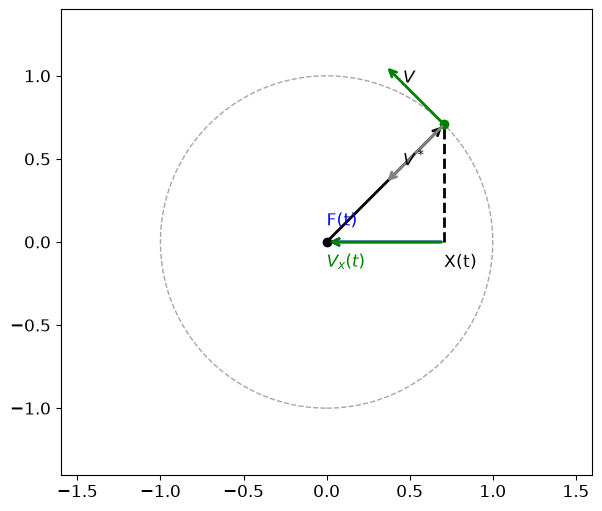

In [6]:
force_controls=animate_parameter(lambda time:show_circle(time,True),0,8*np.pi,np.pi/4,.08,'Time')

Now apply a harmonic force with frequency $\omega\ne\omega_0$. The motion contains both natural and forced contributions:

$$
a=-{\omega }_{0}^{2}x + f\left(\omega  t\right), f\left(\omega  t\right)={f}_{0}\cos{\left(\omega  t+{\varphi }_{0}\right)}
$$

own and forced oscillations. Accordingly, both velocity and displacement can be represented as the sum of two contributions corresponding to different frequencies:

$$
x\Rightarrow {x}_{{\omega }_{0}}{e}^{i {\omega }_{0}t}+{x}_{\omega }{e}^{i \omega  t}
$$

That is there is an addition of two oscillations with the own frequency and the frequency of the external force.

$$
-{\omega }^{2}{x}_{\omega }=-{\omega }_{0}^{2}{x}_{\omega }+{f}_{\omega }\Rightarrow {x}_{\omega }=\frac{{f}_{\omega }}{{\omega }_{0}^{2}-{\omega }^{2}}
$$

At the same time, when $\omega <{\omega }_{0}$, the particle as a whole follows the external force, and when $\omega >{\omega }_{0}$ the displacement is in antiphase. This is definitely a manifestation of the inert properties of the system.

The real solution is

$$
x\left(t\right)={x}_{0}\cos{\left({\omega }_{0}t+{\varphi }_{0}\right)}+\frac{{f}_{0}}{{\omega }_{0}^{2}- {\omega }^{2}}\cos{\left(\omega  t+{\alpha }_{0}\right)}
$$

The case

$$\omega=\omega_0$$

in which the amplitude increases indefinitely, is called resonance and the solution is not harmonic as the amplitude grows linearly with time

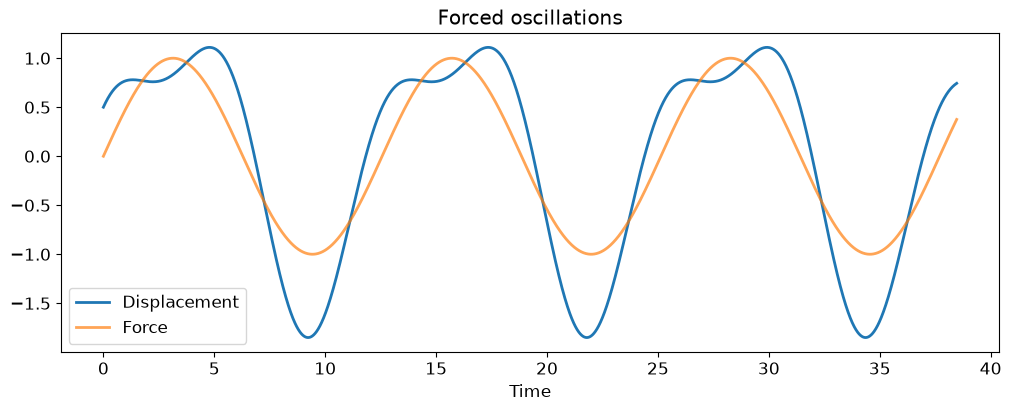

interactive(children=(FloatSlider(value=0.5, description='w', max=2.0, min=0.1, step=0.01), FloatSlider(value=…

In [7]:
def forced_displacement(t,w,x0,v0):
    if abs(w-1)<1e-9: response=.5*(np.sin(t)-t*np.cos(t))
    else: response=(np.sin(w*t)-w*np.sin(t))/(1-w*w)
    return x0*np.cos(t)+v0*np.sin(t)+response
def show_forced(w=.5,x0=.5,v0=.5):
    tmax=10*np.pi/(2*(w-1)**2/((w-1)**2+.5)+.15); t=np.linspace(0,tmax,3000)
    fig,ax=plt.subplots(figsize=(10,4),layout='constrained'); ax.plot(t,forced_displacement(t,w,x0,v0),label='Displacement')
    ax.plot(t,np.sin(w*t),label='Force',alpha=.7); ax.set(xlabel='Time',title='Forced oscillations'); ax.legend(); plt.show()
show_forced()
forced_controls=widgets.interactive(show_forced,w=widgets.FloatSlider(min=.1,max=2,value=.5,step=.01),
    x0=widgets.FloatSlider(min=0,max=1,value=.5,step=.05),v0=widgets.FloatSlider(min=-10,max=10,value=.5,step=.1))
display(forced_controls)

Near resonance, the natural and driving frequencies are close and the motion exhibits beats: their relative phase changes slowly, producing alternating growth and decrease of the resultant amplitude.

An example of acoustic beats

In [8]:
sample_rate=22050
audio_time=np.arange(10*sample_rate)/sample_rate
beats=np.sin(2*np.pi*440*audio_time)+np.sin(2*np.pi*440.5*audio_time)
display(Audio(beats,rate=sample_rate,normalize=True,autoplay=False))

Task: Show that in case of resonance the amplitude of oscillations increases linearly with time.

$x''\left(t\right) = -{\omega }_{0}^{2} x+{f}_{0}\cos{\left({\omega }_{0} t+{\alpha }_{0}\right)}\Rightarrow \text{substitute } x\left(t\right)={x}_{0}\cos{\left({\omega }_{0}t+{\varphi }_{0}\right)}+a t \sin{\left({\omega }_{0} t+{\alpha }_{0}\right)}$ and find coefficient $a$

In [9]:
t,w,a,f0=sp.symbols('t omega a f_0',real=True)
trial=sp.cos(w*t)+a*t*sp.sin(w*t)
resonant_residual=sp.simplify(sp.diff(trial,t,2)+w*w*trial-f0*sp.cos(w*t))
display(resonant_residual,sp.solve(resonant_residual,a))

(2*a*omega - f_0)*cos(omega*t)

[f_0/(2*omega)]

As you can see, the forced oscillations are not harmonic, but are represented as a sum of harmonic oscillations. However, with a special choice of initial conditions, oscillations can occur with the frequency of the external force. It is clear that this will happen if the initial displacement and velocity satisfy certain relation.

Task: establish such a relation

$$x\left(0\right)=\frac{f\left(0\right)}{\omega_0^2-\omega^2},\qquad v\left(0\right)=\frac{\omega\sqrt{f_0^2-f\left(0\right)^2}}{\omega_0^2-\omega^2}.$$

The source writes the positive square-root branch. In general the velocity sign depends on the forcing phase; equivalently, $v\left(0\right)=f\prime\left(0\right)/\left(\omega_0^2-\omega^2\right)$.

Note that the equation

$$
x''=-{\omega }_{0}^{2}x + f\left(t\right)
$$

can be integrated for arbitrary $f\left(t\right)$. Let’s introduce complex function $\Xi \left(t\right) = x'\left(t\right)+i {\omega }_{0} x\left(t\right)$

$$
\Xi '\left(t\right) = -{\omega }_{0}^{2}x\left(t\right)+i {\omega }_{0} x'\left(t\right) + f\left(t\right) = i {\omega }_{0}\Xi \left(t\right)+f\left(t\right)
$$

Then

$$
\Xi \left(t\right) = {e}^{i {\omega }_{0}t} \left({\int }_{0}^{t}{e}^{-i {\omega }_{0}t'} f\left(t'\right)dt'+\Xi \left(0\right)\right)
$$

$$
x\left(t\right) =\frac{Im \Xi }{{\omega }_{0}}
$$

### Forced oscillations with viscous damping

In real systems, there is friction, which leads to damping of self-oscillations, since their energy is converted into heat. Let’s write the equation of motion if the force of friction is proportional to the speed (viscous friction):

$$
a = -{\omega }_{0}^{2} x-\gamma  x'\left(t\right)+{f}_{\text{ext}}\left(t\right)
$$

For forced oscillations we get:

$$
-{\omega }^{2}{x}_{\omega }= -{\omega }_{0}^{2} {x}_{\omega }-i \omega  \gamma  {x}_{\omega }+{f}_{\omega }
$$

$$
{x}_{\omega }=\frac{{f}_{\omega }}{{\omega }_{0}^{2}-{\omega }^{2}+i \gamma  \omega }
$$

or for real amplitudes

$$
{x}_{0}=\frac{{f}_{0}}{\sqrt{{\left({\omega }_{0}^{2}-{\omega }^{2}\right)}^{2}+{\gamma }^{2} {\omega }^{2}}}
$$

which gives typical damped resonance curve

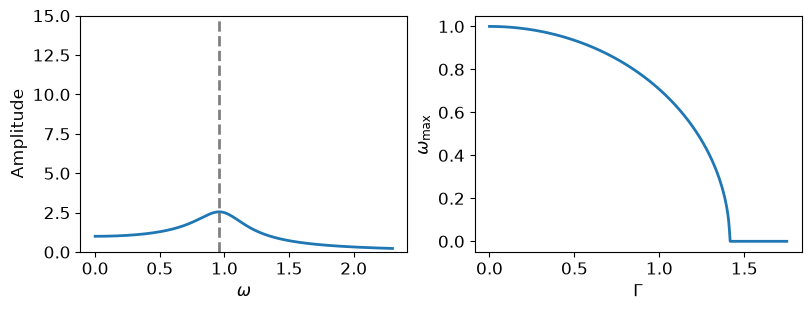

interactive(children=(FloatSlider(value=0.4, description='g', max=1.1, min=0.08, step=0.02), Output()), _dom_c…

In [10]:
def peak_frequency(g): return np.sqrt(np.maximum(0,1-np.asarray(g)**2/2))
def show_resonance(g=.4):
    w=np.linspace(0,2.3,800); amplitude=1/np.sqrt((1-w*w)**2+g*g*w*w)
    fig,axes=plt.subplots(1,2,figsize=(8,3),layout='constrained')
    axes[0].plot(w,amplitude); axes[0].axvline(peak_frequency(g),ls='--',color='gray'); axes[0].set(xlabel=r'$\omega$',ylabel='Amplitude',ylim=(0,15))
    damping=np.linspace(0,1.75,400); axes[1].plot(damping,peak_frequency(damping)); axes[1].set(xlabel=r'$\Gamma$',ylabel=r'$\omega_{\max}$'); plt.show()
show_resonance()
resonance_controls=widgets.interactive(show_resonance,g=widgets.FloatSlider(min=.08,max=1.1,value=.4,step=.02))
display(resonance_controls)

It can be seen that the oscillations of the coordinates are phase-shifted relative to the oscillating forcing force by a certain phase angle:

$$
{x}_{\omega }~{f}_{\omega }{e}^{i \varphi },  \tan{\varphi \left(\omega \right)} = \frac{\gamma  \omega }{{\omega }^{2}-{\omega }_{0}^{2}}
$$

For the convention $e^{i\omega t}$, the displacement lags the force by an angle between $0$ and $\pi$, passing through $\pi/2$ at $\omega=\omega_0$. Use the correct quadrant when evaluating the phase. At high frequency, the displacement response falls as $1/\omega^2$. This is one ingredient in oscillator models of optical response; transparency also depends on the material’s absorption processes.

As an example of application of the presented material, consider the following problem

## Problem

A body m attached to a spring k subjected to external viscous force F=-γv, γ>0 . When the spring is undeformed the body gains initial velocity ${v}_{0}$ and additional harmonic force begins to act. It appears that the energy of established oscillations is equal to initial one. Find the frequency of harmonic force and its amplitude.

### Solution

The initial energy of the system:

$$
{E}_{0}=\frac{m {v}_{0}^{2}}{2}
$$

In the notation of the problem, the equation of motion is:

$$
m a= -k x\left(t\right)- \gamma  v\left(t\right) +F\left(t\right)
$$

for established oscillations according to above we have

$$
{x}_{\omega }=\frac{{F}_{\omega }/m}{{\omega }_{0}^{2}-{\omega }^{2}+i \gamma  \omega /m}
$$

For constant instantaneous oscillator energy in the established motion, the external force compensates friction at every instant:

$$
F\left(t\right) = \gamma  v\left(t\right) \Rightarrow {F}_{\omega }=i \gamma  \omega  {x}_{\omega }
$$

Under this constant-energy interpretation, the displacement lags the force by $\pi/2$, $\omega=\omega_0$, and $F_0=\Gamma v_0$. Equality of time-averaged energies alone would not uniquely determine the frequency.

## Motion under external force of high-frequency

In [11]:
# Numerical integration for the high-frequency forcing example.
from scipy.integrate import solve_ivp

Consider motion under a harmonic force with $\omega\gg1/T$, where $T$ is the unperturbed period.

$$
m\frac{{d}^{2}q}{{dt}^{2}}=-\frac{dU}{dq}+f\left(q\right)\sin{\omega t}\tag{HF1}
$$

Because of the system’s inertia one can assume that the motion can be represented as the superposition of slow varying and fast oscillating terms:

$$
q\left(t\right) = Q\left(t\right)+\Xi \left(t\right)\tag{HF2}
$$

$Q$ and $\Xi$ are the slow and fast components, respectively. The small, rapidly oscillating term $\Xi$ averages to zero over times long compared with the forcing period:

$$
{\left\langle q\left(t\right)\right\rangle }_{T}=\frac{1}{T}{\int }_{t}^{t+T}q\left(t'\right)dt' = Q\left(t\right)
$$

Substitute the slow–fast decomposition (HF2) into the equation of motion (HF1) and expand to first order in the small fast displacement:

$$
m\frac{{d}^{2}Q}{{dt}^{2}}+m\frac{{d}^{2}\Xi }{{dt}^{2}}=-\frac{dU}{dQ}-\frac{{d}^{2}U}{{dQ}^{2}}\Xi +f\left(Q\right)\sin{\omega t}+\frac{df}{dQ}\Xi  \sin{\omega t}+o\left(\Xi \right)\tag{HF3}
$$

Therefore, in the leading approximation we can write

$$
m\frac{{d}^{2}\Xi }{{dt}^{2}}=f\left(Q\right)\sin{\omega t}\Rightarrow \Xi  =- \frac{f\left(Q\right)}{m {\omega }^{2}}\sin{\omega t}\tag{HF4}
$$

Average the equation of motion over an interval $T\gg1/\omega$ to obtain the slow evolution:

$$
m\frac{{d}^{2}Q}{{dt}^{2}}=-\frac{dU}{dQ}+{\left\langle \frac{df}{dQ}\Xi  {e}^{\mathrm{i}\omega t}\right\rangle }_{T}=-\frac{dU}{dQ}-\frac{1}{m {\omega }^{2}}{\left\langle \frac{df}{dQ}f \sin^{2}{\omega t}\right\rangle }_{T}=\\ -\frac{dU}{dQ}-\frac{1}{2m {\omega }^{2}}{\left\langle \frac{df}{dQ}f\right\rangle }_{T}=-\frac{d}{dQ}\left(U+\frac{\left\langle {f}^{2}\right\rangle }{4m {\omega }^{2}}\right)\tag{HF5}
$$

From here we see that the time averaged slow evolution is due to effective potential energy:

$$
{U}_{\text{eff}}=U+\frac{{\left\langle {f}^{2}\right\rangle }_{T}}{4m {\omega }^{2}}=U+{\left\langle \frac{m}{2}{\left(\frac{d\Xi }{dt}\right)}^{2}\right\rangle }_{T}\tag{HF6}
$$

The extra effective-potential term is the average kinetic energy of the fast oscillation. It can shift an equilibrium or change its stability, as the following example shows.

### Kapitsa pendulum

Consider the pendulum with vertically oscillating pivot point


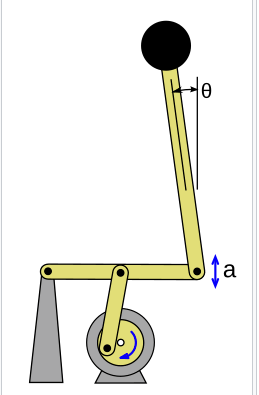



The effective potential energy

$$
{U}_{\text{eff}}=-mgl \cos{\varphi} +\frac{m {a}^{2} {\omega }^{2}}{4}\sin^{2}{\varphi}\tag{HF7}
$$

has φ=0 as stable equilibrium. Another position φ=π is unstable but acquires stability if

$$
a \omega >\sqrt{2 g l}\tag{HF8}
$$

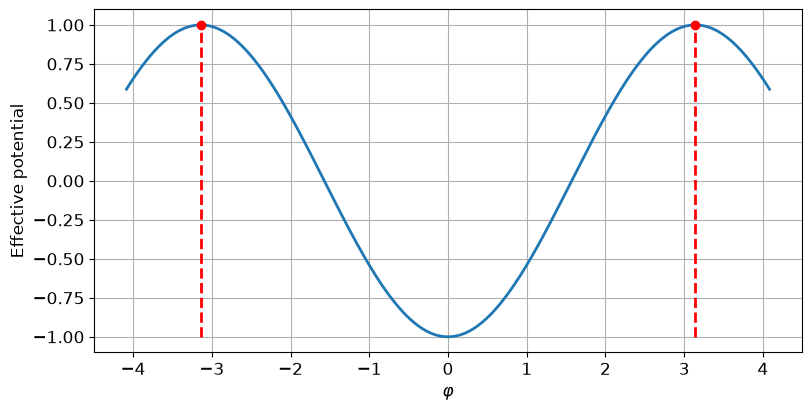

interactive(children=(FloatSlider(value=0.0, description='a', max=10.0), Output()), _dom_classes=('widget-inte…

In [12]:
def show_kapitsa_potential(a=0.):
    q=np.linspace(-1.3*np.pi,1.3*np.pi,1000); potential=-np.cos(q)+a*np.sin(q)**2
    fig,ax=plt.subplots(figsize=(8,4),layout='constrained'); ax.plot(q,potential); ax.plot([-np.pi,np.pi],[1,1],'ro')
    for x in (-np.pi,np.pi): ax.plot([x,x],[-1,1],'r--')
    ax.set(xlabel=r'$\varphi$',ylabel='Effective potential'); ax.grid(); plt.show()
show_kapitsa_potential()
kapitsa_potential_controls=widgets.interactive(show_kapitsa_potential,a=widgets.FloatSlider(min=0,max=10,step=.1,value=0))
display(kapitsa_potential_controls)

Visualize this system with $m=l=g=1$:

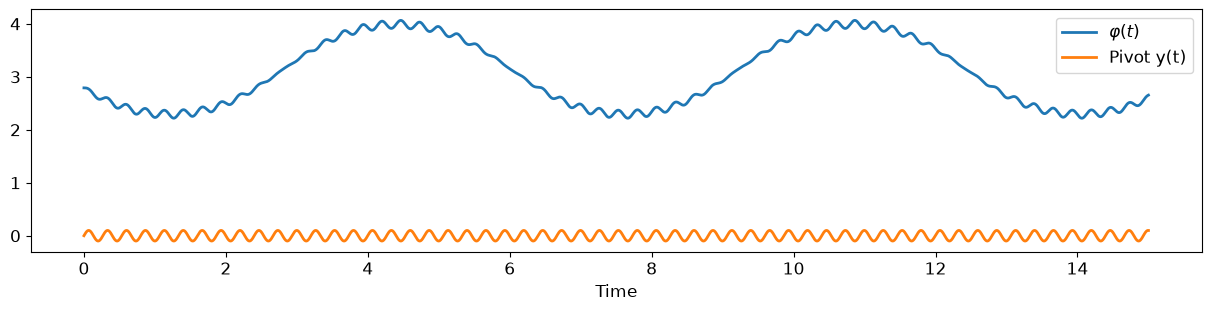

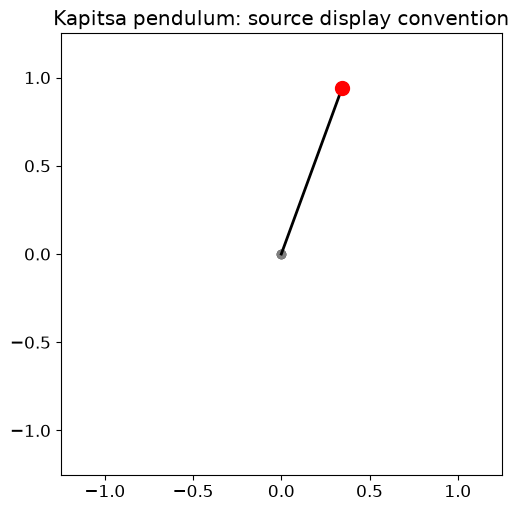

In [13]:
a0=.1; drive_frequency=(5/3)*np.sqrt(2)/a0; tend=15.
def pivot(t): return a0*np.sin(drive_frequency*t)
def pivot_acceleration(t): return -a0*drive_frequency**2*np.sin(drive_frequency*t)
# The source Lagrangian gives phi''=-(1-y'') sin(phi).
def kapitsa_rhs(t,state): return [state[1],-(1-pivot_acceleration(t))*np.sin(state[0])]
kapitsa_solution=solve_ivp(kapitsa_rhs,(0,tend),[np.pi/1.125721231,0],method='DOP853',rtol=2e-10,atol=2e-12,max_step=2*np.pi/drive_frequency/30,dense_output=True)
assert kapitsa_solution.success
times=np.linspace(0,tend,8000)
fig,ax=plt.subplots(figsize=(12,3),layout='constrained'); ax.plot(times,kapitsa_solution.sol(times)[0],label=r'$\varphi(t)$'); ax.plot(times,pivot(times),label='Pivot y(t)')
ax.set(xlabel='Time'); ax.legend(); plt.show()
def show_kapitsa(time):
    angle=kapitsa_solution.sol(time)[0]; y0=pivot(time)
    # The source drawing uses y-cos(phi), although its Lagrangian uses y+cos(phi).
    point=[np.sin(angle),y0-np.cos(angle)]
    fig,ax=plt.subplots(figsize=(5,5),layout='constrained'); ax.plot(0,0,'ko'); ax.plot(0,y0,'o',color='gray')
    ax.plot([0,point[0]],[y0,point[1]],'k-'); ax.plot(*point,'ro',ms=10)
    ax.set(xlim=(-1.25,1.25),ylim=(-1.25,1.25),aspect='equal',title='Kapitsa pendulum: source display convention'); plt.show()
kapitsa_controls=animate_parameter(show_kapitsa,0,tend,0,.05,'Time')

## Harmonic circuits. Impedance.

Electrical RLC circuits provide another example of harmonic motion. Complex amplitudes for charge, current, and voltage turn their linear equations into algebraic relations and make phase differences visible geometrically.

The circuit equations follow from Kirchhoff’s laws and electromagnetic induction: currents sum to zero at a node, and the signed voltage changes sum to zero around a loop.

First, let’s consider alternating current harmonic circuits from linear elements. A generator with a harmonic EMF E(t) of frequency ω operates in the circuit, which we will identify with the complex quantity ${E}_{\omega }$ due to the above. The amplitude will be denoted as ${E}_{\omega }$. At any section of such a circuit, the voltage, current, and charge will also change in a harmonic manner, so let’s use the Fourier amplitudes for these values

$$
{U}_{\omega }, {I}_{\omega }, {q}_{\omega }
$$

It is obvious that by definition and the main property of amplitudes:

$$
{I}_{\omega }=i \omega  {q}_{\omega }
$$

The relationship between current and voltage is given by the impedance - the complex resistance of the circuit section:

$$
{U}_{\omega }={Z}_{\omega }{I}_{\omega }
$$

impedance determines the phase shift between voltage and current

$$
Arg {U}_{\omega } = Arg {Z}_{\omega } + Arg {I}_{\omega }
$$

The series connection of elements by virtue of Kirchhoff’s law leads to the addition of impedances, and the parallel connection to the addition of inverse values

**Series connection:** $Z=Z_1+Z_2$.

**Parallel connection:** $Z^{-1}=Z_1^{-1}+Z_2^{-1}$.

The impedances of standard linear elements are

| Element | Voltage–current relation and impedance | Phase of current relative to voltage |
|---|---|---|
| Resistor | $U=IR$, $Z=R$ | $0$ |
| Capacitor | $U=q/C$, $Z=1/\left(i\omega C\right)$ | $+\pi/2$ |
| Inductor | $U=L\,dI/dt$, $Z=i\omega L$ | $-\pi/2$ |


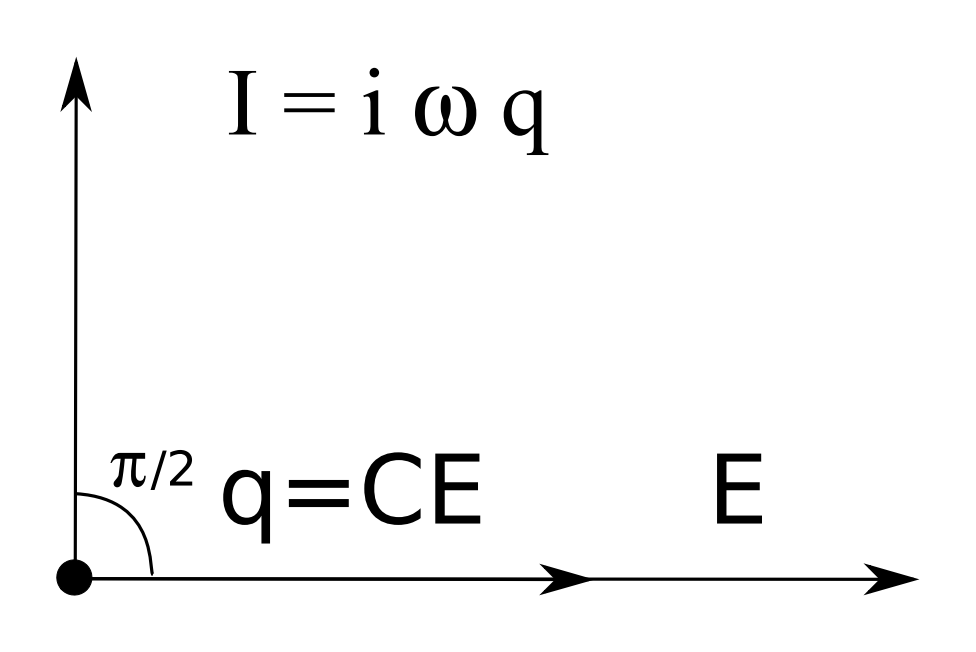


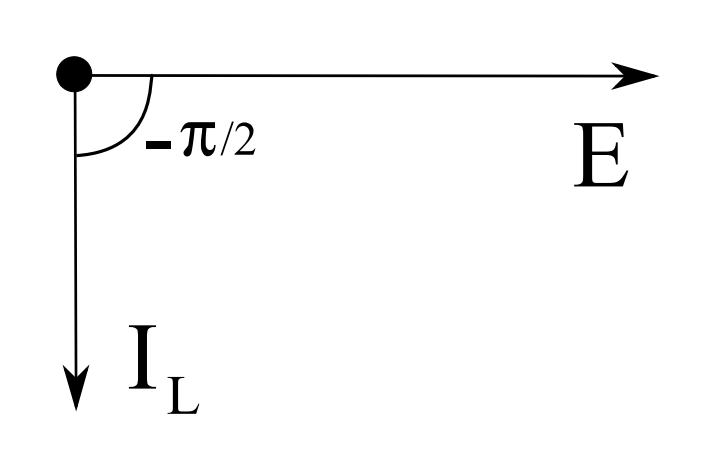

In [14]:
from IPython.display import HTML
# Original lecture figure, embedded for use without external PDF files.
display(HTML('<img src="..." alt="Original lecture figure" width="50%" />'))
display(HTML('<img src="data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAswAAAHUCAYAAAAuvH5xAAAu3ElEQVR4nO3dB5iU5bk38EdAijQrdsXeKxaMBRtYiC12vaxRT+zGEzXxixp7jZoYTTEaG8k5sXuiQb1MONYTG8cSsaBgRcUCiooI8l3Pm2/321123313d9rO8/td11zMzs7OvMwMy3/uuZ/7mW/u3LlzAwAA0KoerV8MAAAIzAAA0A4VZgAAyCEwAwBADoEZAAByCMwAAJBDYAYAgBwCMwAA5BCYAQAgh8AMAAA5BGYAAMghMAMAQA6BGQAAcgjMAACQQ2AGAIAcAjMAAOQQmAEAIIfADAAAOQRmAADIITADAEAOgRkAAHIIzAAAkENgBgCAHAIzAADkEJgBACCHwAwAADkEZgAAyCEwAwBADoEZAAByCMwAAJBDYAYAgBwCMwAA5BCYAQAgh8AMAAA5BGYAAMghMAMAQA6BGQAAcgjMAACQQ2AGAIAcAjMAAOQQmAEAIIfADAAAOQRmAADIITADAEAOgRkAAHIIzAAAkENgBgCAHAIzAADkEJgBACCHwAwAADkEZgAAyCEwAwBADoEZAAByCMwAAJBDYAYAgBy98r6Zqrfeeivcd999YcKECWHixInZ13PmzAmLLrpoWHLJJcOqq64aRo0aFYYPHx7mn3/+ah8uAABlNN/cuXPnlvMOuouPP/44XHXVVWHMmDHh7bffDj179gxffvllq9eN31tggQXCN998E7bccstwxhlnZH8CAFB/kg/MX331Vbj88svDBRdckFWRv/766w4/iDE8r7XWWuHnP/+54AwAUGeSDszjxo0Le++9d1ZJbqua3NHgfOCBB4Zf/epXoXfv3iU5RgAAqivZwHzllVeG008/Paswl1IMzausskrWA73UUkuV9LYBAKi8JAPzqaeemlWBSx2WG/Tq1SsMGjQoPPPMM2Ho0KFluQ8AACojucB87bXXhpNOOqkkLRh5evTokU3UeP7558PCCy9c1vsCALqnGMNuvPHG7PyOO+4YllhiiWofEqkH5qeffjpstdVWZasstxRHzm2yySbhv//7v7PJGgAALc2cOTPsvvvu4f777w8bbrhh2GmnncLOO+8cNt10U/mhRiQTmD///POw0korhalTp1b0fmNP86WXXhqOOeaYit4vANA9Q3NT++67bxaed9hhh7D44otX7fhSl0xgPvfcc8OFF15YsepyU7Gf+Z133gkDBw6s+H0DAN07NDfYaKONsupzPMVPsH16XTlJBObPPvssm1jxxRdfVOX++/XrF0444YRw0UUXVeX+AYDuE5oHDx4cZs2alXu9uD4qVp1jeI69z4sttljFjjFFSQTms88+O1x88cVVqS436Nu3b/j000+zPwEAOltpbmm++ebLqs+xdSMG6Hhe9bm0kgjMsXf5jTfeqOoxxHaMP/3pT2H06NFVPQ4AoHuE5t122y088MADHf7ZRRZZJKs6x/Acq9CLLrpoWY4xJXUfmKdMmZLNQm7vo41KOOCAA8KYMWOqfRgAQDcQPxmPlebOhOam1efY79wweWPYsGHZ6Fs6pu4D8w033BCOP/74MGPGjGofStaTNG3atGofBgCQUGhuKvY6N1SfR40alVWjaV/dB+Zjjz02XHPNNaEWxH6iuAAxjpoDACgammN7xoMPPljSByxWmuOs54bJG3EGtOpzooE5vsDuueeeUAsGDBiQbZe96qqrVvtQAIBupFyhuakhQ4Zk1efYuhGrzwsttFDZ7qu7qfsmltjDXCtihfntt98Oqfjkk0+yEwDQ9RG1d999dxg5cmTZHsoPP/ww3HTTTWG//fbLFgpuscUW4fzzzw/PPvts+Pbbb0PK6r7CvPrqq4dXXnkl1ILYeL/ggguGPn36ZOebXt7yekW+15HrVvp78R/Wa6+9lvVGxX6pev/7luN71b5/f1+PRaVeF9V+7Xmte3670+v566+/zvZ1eO6550IlLbTQQlmm2nPPPcP3v//9LM+kpO4D84gRI8LDDz9c7cMAAKgLPXv2DJtttlnj3Of11ltvnoBfb3qFOrfCCivUTGCOL6all156nmHiTd+ztHz/Us3vdeV24lSS2bNnZ+d79+7dbMOWStx/Jf7+AJCiOXPmhPHjx2e7DcZKc8w29b7TYN0H5pVXXjkLqPHJrbZevXqF119/PQuQ9W7FFVcMkyZNys7//ve/DwcddFCoZ7UW5uv9/mv52Kp9/7V8bKnffy0fW7Xvv5aPrdr33/J7Mc/ccccd4cknnwzVsMsuu4QTTzwx62+OLaapqPvAHJ/QOMbt888/r/ahhA022CCJsBwry00XN66yyiqh3rXXzwYAXRXXBx111FEVC8txutf222+ftV3E6RnLLbdcSFUSgbkWVnbGd2F77bVXSMF7773X2I4RxZ0WAYDOi1nmyCOPDNdff31ZH8a11167cS7z5ptvnkShr4i6D8yxDSLuox4/vqimOAh89OjRIQWTJ09uPB97lxdffPGqHg8AdGflDMsDBw7MRtXFgBzz0rLLLlvy+6gHdR+Yo+OOOy6MHTs2fPnll1Vtx1hzzTVDaoE5Vpe1JwBA58PyEUccEf7whz+U7CGMUy0atsf+zne+E+aff35PTzuSCMzbbLNNFlgff/zxVicdxEBXzgkIsYf6sssuC6loGpiXX375qh4LAHRXcYFfDMs33HBDl25n8ODBjVXkGJSXWmqpkh1jKpIIzNHVV1+dzQyMW0s2tEg09DaXMyzHCR0xrMf7TsWbb77ZeF5gBoDOheW4QciNN97YqYcvZo+GKnLMILFFlc5L5tGLHz/ErR7/+Mc/ZrvkVGohYKwux/tMicAMAJUNy3Ee8qhRoxp7kZdccklPQQklE5ijX//61yXtASqy7/utt96a3BiWt956q/F8an93AOhqWI7V4RdeeKHd6w4bNqyxzWLTTTdVRS6jpAJzHO02ceLEsOWWW4YPPvigrFXmWFk+7bTTsnd5KYmPadPArCUDAIqH5cMOO6zNsBx31mtaRTaFqnLmm5vgfr+xZWDrrbcO77//fpg5c2ZZKstnnHFG+MlPfhJSEx/Tph8DxcdalRkAioXlm2++udnlG2+8ceNc5Hg+ro2i8pKqMDeter744ovh4IMPLum4ufgijlXsm266Key5554hRU37l+PjYSUuALQflg899NBwyy23hEUWWSSrHsepFnH/hsUWW8zDVwOSDMxR//79w2233RZ+85vfZK0T8cXaleAcq8rbbbdd+OUvfxlWWGGFkKqm7RhLL720fioAyBE/6I9ZZOWVVw7/+Mc/sr5kVeTak2xgbpi/fPTRR4eDDjooXHXVVeHCCy/MLp8xY0ahUXMxJMee3bXWWisbWzd8+PCQOhMyAKBjWeTYY4/1kNW4HtU+gFowYMCArN849t+OGTMmG+US+3DjzMJYiY6nBvFdX9wRJ46pu+CCC8Krr74annnmGWG5lcCsdxkAqAdJV5hbm2yxyy67ZKfos88+Cx999FF46KGHwlFHHZVdduaZZ2YL+mz33Lo33nij8bwJGQBAPRCYcwwaNCg7TZkypVmoFpZbF9tYnn766cav11577dK9UgEAqkRLRgFNA3KCU/g6tODvww8/bPx6k002qerxAACUgsBcgIpyMU8++WSz4eorrrhiZ1+XAAA1Q2DuIBXmYoE5Vpe90QAA6oHAXICWjM4FZgCAeiAwFyAwt2/27NnNFvwJzABAvRCYCxCY2/fSSy812ykx7ncPAFAPBOYC9OJ2rB1j6NChYciQIV15XQIA1AyBuYMs+ms/MG+66aZdeU0CANQUgbkALRnte/TRRxvP618GAOqJwFyAwJxv4sSJYcKECY1fjxgxoquvSwCAmiEwFyAw57v77rsbzy+zzDJhww037OrrEgCgZgjMBQjM+e65557G87vuuqtFkgBAXRGYCzAlo20fffRRs/7lGJgBAOqJwNxBpmQ0d99994Vvv/02Oz9w4MCw9dZbl+q1CQBQEwTmArRkFOtf3nHHHUOfPn1K8boEAKgZAnMBAnPrpk+fHsaOHdv49W677Vaq1yUAQM0QmAsQmFt38803N26H3bdv3zB69OhSvjYBAGqCwFyAwNx6L/c111zT+PX+++8fFlxwwVK+NgEAaoLAXIApGfMaN25cs81Kjj322FK+LgEAaobA3EGmZPxL0+py3Ap72LBhpXxdAgDUDIG5AC0Zzb377rvhzjvvbPz6mGOOKfXrEgCgZgjMBQjMzV177bVhzpw52fmFF1447LvvvuV4bQIA1ASBuQCB+f+LUzF++9vfNn79/e9/P5uQAQBQrwTmAiz6+/9+/vOfh/fff/9fL54ePcIPfvCDcr02AQBqgsDcQSkv+psyZUq4+OKLG78+/PDDw4orrljVYwIAKDeBuQAtGf9y1llnhS+++CI7379//3DOOeeU87UJAFATBOYCBOYQXnzxxXDdddc1PiannnpqWHLJJcv52gQAqAkCcwECcwinnHJK+Pbbb7PHY6mllgr//u//Xu7XZvKmT58eLr/88nDrrbcm/1gAQDX1quq9dxOpB+YHHnggjB07tvHr888/P2vJ6E5mzZoVbrnllnD77beHTz75JMycObPs9/nUU0+FXr06/0/srrvuyt6Y/OxnP8u93meffRZuu+22MHHixKxlJj43yy+/fNhnn33CQgst1On7BwD+RWAuIOUpGTFYnnzyyY1fr7feeuGggw4K3Ums0l522WXZosVK6uqbqz//+c/ZnzH4ttUmE/9esQIdx/21dOKJJ4a99torHHfccWH48OFdOhaAerHtttuGt956K3RXiy++eHjssceqfRjJEZg7KLUKc6xw/vOf/2w2Vq5nz56hu/jhD38YrrzyytDdxCp4rOyvs846YY011pjn+3fffXc44IADWg3KDb7++uswZsyY8Kc//SlcccUV4YQTTijzUQN0j08c4ym2GcbfobH9raHlsDuYOnVqtQ8hSQJzAam2ZMSP+a+55prGr2NA22677UJ38bvf/a5bhuWGdozZs2e3uovigw8+GPbee+/wzTffzPM6be31Gf8jiNXmr776Kpx22mllPW6AWvfoo4/OU6CIRYj4aV1sP6z1/+c///zz7Pd63AuByplvbq2/MmrA5MmTwworrJCdP+mkk7JqXb17/fXXw4Ybbpj1x0arrLJKeOaZZ8LAgQNDd3nOYmW2Er3KbYkVjPnnn79TP7vDDjtkFeZXX301e+wbxJAcZ1+/8847YcCAAdlOizE8b7rpplnlP24qE98o/OpXvwofffTRPLc7bty4MGLEiC79vQDqVVznEtvgilScDzvssDBo0KAu3V+MYPG+4u/2Dz/8MLz99tvZ6YMPPsj9ufh/c3f5/7huxMBMvsmTJ8c3FdnpxBNPrPuHa+bMmXOHDRvW+Hfu06fP3PHjx8/tTg4//PDG46/WadasWZ069g8//HBuz549526wwQbzfG/MmDHZbW+88cbZ67It06dPn7vFFlvMc0yjR4/u1DEBpOKoo44q9Dt+0qRJZTuGeNtnnnnm3MGDB7d63++8807Z7pvWqecXkFpLRvzYPlaTG8SK+vrrrx+6U3X8pptuys6vueaaWbU1VpxnzJiRTZGIp9NPP73Zz+yyyy6N32vttP322ze7/kUXXZR7/XjqbHX5zjvvDHPmzJmnHSO+9mIP+UorrRT+9re/ZZMw2hKrHvfee29Ye+21m10eL3vppZc6dVwAKdh6662rfQhh6NCh4eyzzw5PP/30PL/Ho4ZPf6kcPcwFpDQlI/bO/uIXv2j8Ok5Z+MEPfhC6k/POOy/r/z3yyCPD1Vdf3Wpwfffdd5t9vcwyy4QFFligzdts2d6w7LLL5l6/K/7zP/8z+zO2WjT1/PPPh/Hjx4eHH344a8doTwzNl156adhpp52aXX7//fdnbyQAmFdrC62rZeWVVw5PPPFE1nbXtNghMFeeCnMH1XOFOYax2JPVIPbK/v73v+9Wbxg+/fTTbDJE7AH+7W9/22aVN1acm2pv18LYW9bUEkssEcoh9q3FPuONN944e/ybevbZZ8Oee+4Ztthii8K3N3LkyLD00ks3u2zatGklO16AerPaaqvV1P97sUDyhz/8YZ6Ff1SWwFxACi0ZMSzHCRgNYSoGzVjpHDx4cOhuCzbiMd9www25v/BaBua8AByf85ZjfIYMGRLKdfxxAUhrs5fjDOxzzjmnQ7cXFwLusccezS7rymYqAPWuX79+7RZRKm2TTTbJCiANVJgrT2AuoN4Dc0NYjtXZBr/+9a/DRhttFLqb73znO9nIoLwAHNs14pSJpvJ+OcZ2jJYj3MoVmBvaMVoLzHFqSWc+Kmx5rLF6AkDb+vTpU3MPz/e+973G8wJz5QnMiQfm+DF/y7AcWxniuLLuKPbmthcIY1iOi+qKBuZJkybN83pYZJFFQqm999574ZFHHgmbbbZZWG655Up2uy1fs5tvvnnJbhugHtXiJ3G77bZbYx4RmCtPYE44MMewHKc/tAzLRx11VKhnb7755jyX5VWkWwbmBRdcsCy7HcaNYuLrq62tsLsyNaTpG4qWPc0ANFeLO9rGwk5c/BcJzJUnMCeqtbAcN7yo97DcWv9y/MW4+OKLF75+DMzlaseIb85aTsfoqqeeeqrx/HHHHVfS2waoR7W06K+p+AlkJDBXnsCcYIU5jqhpGZavvfbabAxbCloG4Fhxzfv47a233mr2dTkWQsadnR5//PFsAkYpK8ATJkzITg2j85pOQQGge2lYW2RKRuUJzAkF5oaNL7baaqt5wvIRRxwRUtEyMLfXL9xyZnM55i/feuut2Z+lbseIizcbnHvuuaFv374lvX0AKmf//ffPFqHHDbmorNrraq9B9RCYP/7443DooYeGv/zlL80uj3OWu+sCv1IF5rwd81oLzOUInX/+85+z11ncKKZU4s6GN954Y3Z+1113DYccckjJbhuAyov/T9TigsQUeNQTCMzxo/799tsv+9i/wcILL5xtHz169OiQmloLzPF4/vGPf2TbsZZyQ5Srrroq63OL/dndbQMaAKglWjIK6K5BI26Acckll2QtGE3DcpxV/L//+79JhuU4Tq7lDOb2AnPLbbF79+5d8upytO+++5bsNl955ZVw9tlnZ+evv/76sNhii5XstgEgNSrMHdRdKszPPfdcOProo7MFfk2ddtppWS9rW1tG1/KbilI89jEsx41Lmmq5BXVLLTctKbUYmHv06JFte10K8e8X22y+/vrr8MMf/jDsvPPOJbldAEiVCnOdtWTElbMnn3xyGDZsWLOwHDfauO+++8JFF11U8rDc3Wcwr7TSSm1ev2W4LrWJEyeGZ555Jmy77bYlqwL/7Gc/C4899li2Jfall15aktsEoHK++uqrcOKJJ2Z7I1AbBOY6Ccyx1eCPf/xjtnXyFVdc0Wwnu7iTX2zB2GmnnULq3njjjXnaK/KmZJS7utwwHaNU7Rh//etfw/nnn5+13YwZM6Ymh+8DkO/9998Pv/zlL8M999zjoaoRAnM3D8yxTznuELfeeuuFAw88sNkCtbiALIboBx98MJvBSwhPPvlks4dh6NChuaGy5RbaRUP0zJkzC10vblYSVzzHanBXPf/88+GAAw4Ia6+9djYNpV+/fl2+TQAq78MPP/Sw1xiBuZsG5ngc8Z3nhhtumO0M989//rPxe7EfNu7o9vLLL2czG7vrosVS++KLL8Ldd9/d7LKVV14592daC9PxnX97FlpoofDjH/+43YV5sdc8biITW2a64tVXXw0jR47MdiG8//77s/sHoHuKrXrUFov+CqilwBnHhN18883hmmuuCS+99NI83x81alS48MILsyBNc2eeeWZ47733ml0WW1jyxCptPMV+sgbxzUmsILc1Xi5W+eP3Bw4cWJHpGHEnwhi6o/hpwlJLLdWl2wOguu644w5PQY1RYe6galWYYzg+9thjs22TY/W4ZViOM3wfeeSRrLooLM8rBskrr7xynstj+0J7WlZ/YxiO/cFtiYsro9VWW63ddoy4AHO33XYLnRWr3bFHffr06WHs2LHtVswBqG2ffPJJGDduXLUPgxYE5hpuyYiVyl/84hdh8803D2uttVZWVY67tzUVv/fQQw+Fv//972GLLbao2LF1J6+99lq25XTs924pPq7tWXLJJee5LI7naznPOYpbjp911lmNz01bYpU6nnbYYYdOt0/EX6rxE4U4Yzu252ywwQaFf/app57KHhcAaktcuN3a+hmqS2CuscDcEJJj+I0L9U466aRsp76m+vTpk21zHUPPo48+mo0kq7b4uJT71BnxDUZcUDdt2rRWn9cigXnddddtdavx4cOHh9tvvz27jzjz+K677gobbbRRmDJlSlh99dVzp280tGPEIN/Z8YFxvnIMvbEve8SIER1q4fjud7+b9boDUDviJ4WtfRpK9elhrnJgjj3JDz/8cPjb3/6WneIisLassMIK2WYkhx9+eJcXiaUibuDRdEFky/nLCyywQLu3seuuu4brrruu1Tc3e+21V6s/873vfa/N24uvodiOEd/4dKYdI7Zf7LLLLuGFF17I2j+22WabQj8Xq99xjN3pp58eVl111dz50wBURvw/YdKkSeGmm24K5513XqufhlJ9AnMFA3P82fjxeZyJ/D//8z9ZQH766adzP3qJm1nE8BUnYcQ+ZXN1i4sV+IZKbmtiNbiI2DYR2zJi5biIuEjwmGOOafP7MejGCRm77757GDRoUOiIqVOnhh133DE8++yz2USME044Iff1Fn/xxs1XYshuOqYojiAEoPNiwO1M8Sr+Tp41a1b48ssvszwQNxn74IMPPBU1TmAu05SM+DH966+/ns3GHT9+fPaPIp5ila89DSE5fly/1VZbZXN66bi4CDLPlltuWeh2YiX4pz/9abbosoi4HXVcnNmWWF3uTDtGbKWIPcsxbEexzaS1VpP2xDddnW0FAeBfGtarkAZJrINixS4utoqn2Mca3xVOnjw523K56Z/xe0XF8WRxgVjsRY6nWPkUkrsub+OOGBpHjx5d+LaOPPLIrK+svYVyG2+8cTjjjDNyq76x6h2f89hWUVR88xVbL+InFF0VK+al2oYbAFIgMHewwhxbKbraPxw/hl9//fWzhVoxIMfFY23N9KXz9txzz3DyySdnY+BaOuqoo8Lyyy9f+Lbi+Le4uC5W/D/66KM2w3Ic65f3XMZPGyZOnJgd24ABAwrff9yEJi4kjKeuymsXAQDmJTB3MDD37t07dEQMZTEcNz3Fy2ppM5R6NWTIkHDjjTeGgw8+OJti0SAu1IuTSDoqbnISp5LEkXJxjFtDP3vcXjsG8B/96EdZsM4TPzmI4wHzRs61JlbDO1IRB6C83njjjez3f2c+qY49zHGO/oQJE7J9FeKUpccee6wsx0lpzDe3VvZ6rmExbDVUDddZZ51s0VZD+Fl00UWz8WHxH008xTDc9Hz//v2rfPTExW633XZb9jzGCvGwYcO6/KDE1pu4CDA+/zYLAagva665ZhZm88TJFp0JzG2Jeyrsv//+2eLuBnF86L333luy+6DzVJgLaFoNXnHFFbN3grEtI7ZWqBR3j0pzqdsQ4puhjrR0AECeuGtr/BQzTsQqOpWJyrFzQQfFiQkxNA8ePFhYBgBKJs7Iv+SSSzyiNUhgruGtsQGAtOy7777aOWuQwFyAwAwAVEJcPL7JJpt4sGuMwFyAwAwAVEocN0ttEZgLEJgBgEopxTQnSktgLsAkDACgUlZZZRUPdo0xVq6DLPoDAModmC+66KJsKhe1QWAuQEsGAFAp/fr1y3aVpXZoyeggFWYAgLQIzB2sMgvMAABpEZgLEpgBANIkMBdkUgYAQJoE5g7SkgEA1IqxY8eGK6+8Mrz55pvVPpS6ZkpGQVoyAIBaMnXq1LDPPvuEWbNmhcMOO6zah1PXVJgLEpgBgFpy7rnnhs8//zzsvPPOYfDgwdU+nLomMBckMAMAteKll14Kv/nNb7Lz+++/f7UPp+4JzAVZ9AcA1IJvvvkmHHLIIdmf/fv3D6NHj672IdU9gbmDLPoDgPpW6//Xx22zn3766ez8brvtFhZYYIFqH1LdE5gL0pIBAGmYM2dOu9f59ttvQzWMHz8+nHPOOY1fa8eoDIG5IIEZANIQp060J7ZDVNpXX30VDj744DB79uzs64UWWiiMGjWq4seRIoG5IIEZANJox4jj2trTEForJQb0vffeO7z44ouNl+25556hd+/eFT2OVAnMBQnMAFD/ZsyYEb788st2r1fkOqWseB944IHh3nvvbXb5fvvtV7FjSJ3AXJApGQBQ/95+++1C13v++edDJUycODGMHDky3Hrrrc0uX3zxxcPWW29dkWNAYK67lbMAQOe1rOK25frrry9rW8Znn30WzjvvvLD22muHhx9+eJ7vxx3+evbsWbb7pzlbYxekJQMA6tvrr78eLr300kLXffzxx8OIESPCKaecEjbccMPQr1+/0KdPn8KfSMcpG3EaRwzdH330UZgyZUp2euedd8Kjjz4aHnrooTBz5sw2f147RmUJzAUJzABQn2J4veOOO8LJJ59caMFf09C8xx57hEpbbrnlwvDhwyt+vykTmAsSmAGg+3vggQeyBXuxujtt2rTwxBNPZNXcyZMnh+4iVpd79LAMrZIE5oIEZgDo/o4++ujwxhtvhO5MO0blCcwFmZIBAN3fGWecEaZPnx66qzh3ef3116/2YSRHYO4gUzIAoPs69NBDq30IdEMaYArSkgEAkCaBuSCBGQAgTQJzQQIzAECaBOaCBGYAgDQJzAAAkENgLkiFGQAgTQJzQQIzAECaBOaCBGYAgDQJzAUJzAAAaRKYC7I1NgBAmgTmDrI1NgBAWgTmgrRkAACkSWAuSGAGAEiTwFyQwAwAkCaBuSCBGQAgTQJzQaZkAACkSWDuIFMyAADSIjAXpCUDACBNAnNBAjMAQJoE5oIEZgCANAnMBQnMAABpEpgLMiUDACBNAnMHmZIBAJAWgbkgLRkAAGkSmAsSmAEA0iQwFyQwAwCkSWAuyKI/AIA0CcwdZNEfAEBaBOaCtGQAAKRJYC5IYAYASJPAXJDADACQJoG5IIEZACBNAnNBpmQAAKRJYO4gUzIAANIiMBekJQMAIE0Cc0ECMwBAmgTmggRmAIA0CcwFCcwAAGkSmAsyJQMAIE0CcweZkgEAkBaBuSAtGQAAaRKYCxKYAQDSJDAXJDADAKRJYC7Ioj8AgDQJzB1k0R8AQFoE5oK0ZAAApElgLkhgBgBIk8BckMAMAJAmgbkggRkAIE0Cc0GmZAAApElg7iBTMgAA0iIwF6QlAwAgTQJzQQIzAECaBOaCBGYAgDQJzAUJzAAAaRKYCzIlAwAgTQJzB5mSAQCQFoG5IC0ZAABpEpgLEpgBANIkMBckMAMApElgLkhgBgBIk8AMAAA5BOaCVJgBANIkMBckMAMApElgLkhgBgBIk8BckMAMAJAmgbkgW2MDAKRJYO4gW2MDAKRFYC5ISwYAQJoE5oIEZgCANAnMBQnMAABpEpgLEpgBANIkMBdkSgYAQJoE5g4yJQMAIC0Cc0FaMgAA0iQwF6QlAwAgTQJzJwKztgwAgHQIzAUJzAAAaRKYC9KSAQCQJoG5E7RkAACkQ2AuSEsGAECaBOaCBGYAgDQJzAUJzAAAaRKYC7LoDwAgTQJzJ1j0BwCQDoG5IC0ZAABpEpgLEpgBANIkMBckMAMApElgLkhgBgBIk8BckCkZAABpEpg7wZQMAIB0CMwFackAAEiTwFyQwAwAkCaBuSCBGQAgTQJzQQIzAECaBOaCTMkAAEiTwNwJpmQAAKRDYC5ISwYAQJoE5oIEZgCANAnMBQnMAABpEpgLsugPACBNAnMnWPQHAJAOgbkgLRkAAGkSmAsSmAEA0iQwFyQwAwCkSWAuSGAGAEiTwFyQKRkAAGkSmDvBlAwAgHQIzAVpyQAASJPAXJDADACQJoG5IIEZACBNAnNBAjMAQJoE5oJMyQAASJPA3AmmZAAApENgLkhLBgBAmgTmggRmAIA0CcwFCcwAAGkSmAuy6A8AIE0CcydY9AcAkA6BuSAtGQAAaRKYCxKYAQDSJDAXJDADAKRJYC5IYAYASJPAXJApGQAAaRKYO8GUDACAdAjMBWnJAABIk8BckMAMAJAmgbkggRkAIE0Cc0ECMwBAmgTmgkzJAABIk8DcCaZkAACkQ2AuSEsGAECaBOaCBGYAgDQJzAUJzAAAaRKYCxKYAQDSJDAXZEoGAECaBOZOMCUDACAdvap9AN1FvbZkTJ8+PRx22GEVu7+bb7459O/fv2L3BwDQVQJz4oF51qxZ4c4776zY/c2ePbti9wUAUAoCc+KBeZFFFgnTpk1rDLPvvfdeGDduXPiv//qv8OCDD3bqNvv27Rt23333cMABB4R11103DBgwIPTq9a+X2qBBg0p6/AAA5SYwJ77or0ePHmHw4MHNAvQ666wTjj/++PDEE0+Egw8+OEycOLHw7a211lrh9ttvD6uttlqZjhgAoLIs+uuEeqow59lss83C3//+9zBkyJBC1x84cGC4//77hWUAoK4IzIm3ZLRnmWWWCUceeWSh68Zq9NJLL132YwIAqCSBuaBUA3NDpbmI2MoBAFBvBOaCUg7MSy65ZKHrrbnmmmU/FgCAShOYC0o5MC+11FKFrrf66quX/VgAACpNYE58SkYRcXJGEQsvvHDZjwUAoNIE5k5IrcLcMEO5vTcUPXv2rMjxAABUksBcUMotGfHv3l6FvUioBgDojgTmglIOzFF7gTnllhUAoL4JzAWlHpgBAFIlMBckMAMApElgLkjLAQBAmgTmTtCSAQCQDoG5IC0ZAABpEpgLEpgBANIkMBckMAMApElgLsiiPwCANAnMnWDRHwBAOgTmgrRkAACkSWAuSGAGAEiTwFyQwAwAkCaBuSCBGQAgTQJzQaZkAACkSWDuBFMyAADSITAXpCUDACBNAnNBAjMAQJoE5oIEZgCANAnMBQnMAABpEpgLMiUDACBNAnMnmJIBAJAOgbkgLRkAAGkSmAsSmAEA0iQwFyQwAwCkSWAuyKI/AIA0CcydYNEfAEA6kg3M06ZNq0hLxrfffhvef//9Dt0XAAC1I9nA/Oabb4YLLrigrIE5Xu+4444LM2bM6NQxAgBQfckG5nXXXTdcffXV4bzzzitLYI7XOf7448MDDzwQVl555S4dKwAA1ZNsYI4BeOeddw5nnHFGOOeccwpdv2hgjt8/8cQTs0C+0047leR4AQCojmQDcxQDc3TWWWeFU089tSRTMmJYPuSQQ8JVV12Vfb3jjjuW4EgBAKiWpAPzdttt13j+0ksvzYJz0XaLti4/+eSTw80339x42dZbb12iowUAoBqSDsyDBg1q9nVszTjzzDNbDcTttWTEy370ox+FK6+8stnP9O/fv+THDQBA5SQdmKPLLrus2ddxEeBPf/rTeUJxXmCOX8eWjssvvzz3tgEA6H6SD8wNfcxNxXFz/+f//J9mwbitwBzP//jHP241HOtfBgDo/pIPzKuvvnoYOnToPA/MhRdeGH7yk580huPWAnP8M17nkksumefnl1122bDGGmuU9ckDAKD8kg/MMQiPHj261Qfn4osvDqeddloWjFtOyYiXxSp0vE5r4ji5opM1AACoXckH5rbaMppOzzjllFOatWHE7a7j/OZYhW6LdgwAgPow39yi+zzXsS+//DIsssgiYebMmW1e57vf/W74y1/+kp3ffffdw1133dXmdXv16hU+/vjjeaZwdGc9e/bM3ii0pXfv3uHrr78u6X1+9dVX2XPTFQMGDAh9+vQp2TEBAOkRmJtUmf/617+W5EEdMWJEGDduXKgnPXr0yJ1RPf/884dZs2aV9D6vvfbarEc8BvEZM2Z06GdjgB84cGC44YYbsjc7AACdpSWjQFtGR9VbO8acOXPa3dAlr/rcWUceeWT46KOPwueffx6ee+65cPjhh+dePy6y/I//+I/w9ttvZ9Xp+LPCMgDQVSrM/88bb7wRVlpppVAK48ePD+uvv36oF7HC27dv30LBOlaiy2nvvfcOt9122zyXb7TRRuGxxx7LKssAAKWkwvz/rLjiimG11Vbr8gO6xBJLhPXWWy/Uk1ipLeKTTz4p+7GMGjWq1ctPPPFEYRkAKAuBucRtGbEdo97Gyb388suFrjdlypSyH8taa63V6uXDhg0r+30DAGkSmMsQmOvNhAkTaiYwL7zwwq1eXqRlBACgMwTmJrbccsvQv3//zj+YPXqEkSNHhnoTF9wV8fDDD5f9WOI0jtboXQYAykVgbiLO691+++07/WBuuummbVZAu6vXXnst3HLLLYWu+7vf/S5MmjSprMfTVrtLnBMNAFAOAnMJ2zLqrR0jTp3Ydtttczd0aWrq1Klh6623Dvfff3+7Y+gAALqLXtU+gFqz0047JRWY4yi4N998MzsfNx6JM4/jWLxYVX7kkUc6fHtvvfVW9jjEanucgRwD9JAhQ7LdD6OhQ4eWffQcAEApmcPcinXXXTe88MILHXogF1100fDBBx90uzAYq8Ix0FbKtGnTwuDBg0s+LzsuOIwj/QAASk2FuY22jI4G5jgfuLuF5YbpEkcccUTF7q+tRXsAALVKYG4jMF988cV1344RDRw4MFx77bXVPgwAgJrV/UqiFbDZZpt1uG1ghx12KNvxAABQPQJzG20DbW3B3NYuc5XsAwYAoHIE5hKMl+uu7RgAALRPYC5BCO7KKDoAAGqbwNyGOKIstlq0J/Y6x5nDAADUJ4G5i20ZI0eObNyUAwCA+iMwdzEw618GAKhvAnOOjTfeOCyyyCK5D6DADABQ3wTmHD179swNxOuss05Yeumly/G8AABQIwTmdowePbrN76kuAwDUP4G5HXEDkx49Wn+YjJMDAKh/AnM7Yg/z8OHD57m8f//+YfPNNy/X8wIAQI0QmDs5LWO77bYLvXv3LsdzAgBADRGYOxmYtWPUtyeffDJ8+umn1T4MAKAGCMwFrL/++vOMl9thhx3K9ZxQZTNnzgy77LJL+PLLL6t9KABADRCYC5hvvvmymcxNrbDCCuV6Tqiy6667Lnt+jQwEACKBuaBtttmm8fxmm23m1VOnpk2bFs4666ywxx57VPtQAIAaITAX9G//9m+hV69e2fkYqKiOb7/9ttXL58yZU5LbP/fcc8PHH38sMAMAjQTmggYPHhy22GKL0Ldv37DVVlsV/TFKbPbs2W32HXfV3XffHa644oqw5pprhlVXXbXLtwcA1Id/lUwpPC0jBuZ+/fp5xKrk3XffbfXyt99+O6y00kqdus25c+eGW265JRxxxBHZee0YAEBTKswdDMzGyVXXK6+80urlV199dRZ2OyJe/6mnngp77rlnOPjgg8OsWbOyywVmAKCp+eZ2NGUkLD5UU6dODUOGDKn2oSRpxowZ2bSSl19+udXvr7HGGmHTTTcNgwYNCj179sxODduax+cu9jnHUPz+++9nlepJkyZl55tabrnlwuTJk7PJKAAAkZaMDoghSliunLj4bsqUKVl/8qOPPhouv/zyrPWiLRMmTMhOXbH77rsLywBAMwIzNWvs2LHhwgsvbPw6Vo7XWmutst7nPvvsU9bbBwC6Hy0ZAACQw6I/AADIITADAEAOgRkAAHIIzAAAkENgBgCAHAIzAADkEJgBACCHwAwAADkEZgAAyCEwAwBADoEZAAByCMwAAJBDYAYAgBwCMwAA5BCYAQAgh8AMAAA5BGYAAMghMAMAQA6BGQAAcgjMAACQQ2AGAIAcAjMAAOQQmAEAIIfADAAAOQRmAADIITADAEAOgRkAAHIIzAAAkENgBgCAHAIzAADkEJgBAEBgBgCAzlFhBgCAHAIzAADkEJgBACCHwAwAADkEZgAAyCEwAwBADoEZAAByCMwAAJBDYAYAgBwCMwAA5BCYAQAgh8AMAAA5BGYAAMghMAMAQA6BGQAAcgjMAACQQ2AGAIAcAjMAAOQQmAEAIIfADAAAOQRmAAAIbfu/+AmyxWAjrh0AAAAASUVORK5CYII=" alt="Original lecture figure" width="50%" />'))

The power (instantaneous) released in a section of the circuit with impedance Z is equal to:

$$
P=I U = \frac{1}{2}Re \left({I}_{\omega }^{2}{Z}_{\omega }{e}^{2 i \omega  t}\right)+\frac{1}{2}\left|{I}_{\omega }\right|^{2}Re {Z}_{\omega }
$$

Thus, the average power over the period is determined only by the real part of the impedance and is maximum at zero phase shift between voltage and current (analogous to collinearity of force and velocity). Elements with Re Z ≠0 are called active, elements with Re Z =0 are called reactive. Ohmic resistance is active, a capacitor and an inductor are reactive elements, where there is no loss of current energy, but only its transformation into other forms (electric field of induced charges in a capacitor, magnetic field of a coil). Reactive resistance determines the magnitude of the current and the phase shift. If the impedance is purely reactive, then the current vector ${I}_{\omega }$ is orthogonal to the voltage vector ${E}_{\omega }$.

### Series RLC circuit


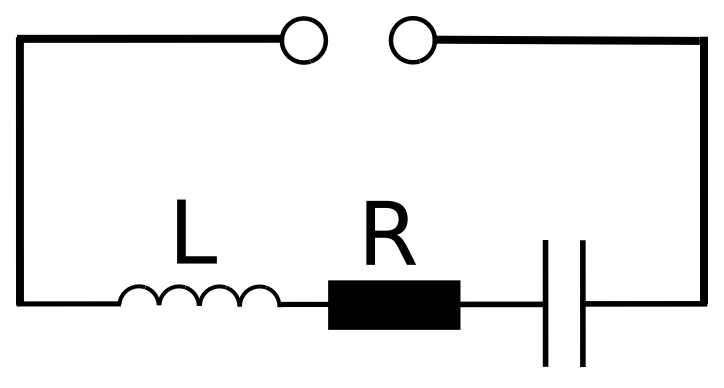

In [15]:
from IPython.display import HTML
# Original lecture figure, embedded for use without external PDF files.
display(HTML('<img src="data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAtQAAAGECAYAAAAWS7eaAAAryklEQVR4nO3dB5xU1b0H8LN0RLGAoqKAgjUq9t7AFnuJaDTWRGPUEH2iJmpswfbQGMsz0fievWONGksUA3aNomLvCioqiKAoIDjvc+7L+nZn2yx3Z+7szPf7+cwHuHPnztl7h9nfnPmfc2pyuVwuAAAA86XD/D0MAAAQqAEAICU91AAAkIJADQAAKQjUAACQgkANAAApCNQAAJCCQA0AACkI1AAAkIJADQAAKQjUAACQgkANAAApCNQAAJCCQA0AACkI1AAUXS6XC1999VX47rvvnG2g4nTKugEAzZk3b17417/+FV5++eUwceLEMGnSpOT2ySefhIUWWigsscQSoU+fPslt+eWXD9tuu21YcsklndQMvf322+G+++4L48ePT65V7XX7+uuvk/sXXXTR5HrFa9e/f//kmm233XZh8cUXd92AdqkmF7sNAMpI7MX8xz/+EW644YZw//33h6lTp7bq8euss07YYYcdwo477hjWX3/9UFNTU7S28n/efffdcP311ye3N954o9WnJV6jeK3iNfvFL34Rll56aacWaDcEaqBszJ49O1x88cXh3HPPDZ999lmbHHOjjTYKI0eODEOHDhWsiyD2PJ944onh2muvbbNjduvWLRx++OHhd7/7XdKLDVDuBGogc/GLsttuuy0cf/zx4b333ivKc2y++eZJsI5/kl4s34gffOLt22+/LcopXWCBBcLw4cOTwN6zZ8+iPAdAWxCogUzF8oBDDjkkPPbYYwXtH2tvl1lmmbDUUkuFmTNnJj3Zn376aVIWUkgF269//evwxz/+MXTp0qUNWl+d/vnPf4Z99903qWNvTqxxX3nllcOyyy6bXLNYxjFnzpzkesXr9tFHH4Vnn322xYGKK620UrjjjjvCKqus0sY/CUDbEKiBzIwdOzbsvvvuYdq0aU3us+mmm4Zdd901GbQWg1VTQTiG6xj0/v73v4d77703fPDBB82WgYwePTr07du3TX6OanL11VeHQw89tMkQHEs09tlnn7DHHnsk57lz587NHi/O/PHwww8n1y2G5ilTpjS634ILLhiuuOKKMGzYsDb5OQDakkANZOK6664LP//5zxsNZh07dkxqaI855piw3HLLtfrYsad63Lhx4ZRTTkn+bCr4xVCtBKTwc3raaaeFP/zhD02ezzPOOCMcfPDBoVOn+ZtAKn4ouuSSS8KoUaOaHIj629/+Npx99tnq4YGyIlADJRcDUayLbczOO++cBKpYKtAWITD2fp5wwgnJ1Hv5unfvnvRqx9klaP48HnbYYeHyyy9vcF/Xrl3DiBEjkgGEscSjLcyYMSMpyznzzDOTaRMbe/3E5wMoFwI1UFI333xz+OlPf9pgewxjcZq8nXbaqc2fM/aCxwB2/vnnN9qz+tRTT81XT3i1+K//+q9kcGC+fv36JeU1q622WlGe95FHHgl77713+Pzzzxvcd+ONNzb6OgLIgkANlExcnGWDDTYI33zzTb3tcdBaDGarr7560cN8nOM4lhbUFQe7Pf7448mCI9QXB4sOGTIkzJ07t972ddddN9x9991FX0QnTsu35557hqeffrpBz3j89mGTTTZxyYDMCdRASUyfPj2st9564a233qq3fc0110zCdKkW8njmmWfClltu2WCqtzjoMa7uZxGY/xdn8Vh77bXD5MmT652rbbbZJhlA2KNHj5JcszhwMda6v/DCCw2+XXjzzTfDwgsvXJJ2ADSlQ5P3ALShWDKQH6bjFHilDNNRrJeO5QL5wfmBBx4Id911V8na0V6uWX6YHjhwYLjllltKFqZry4HuueeeBrOyxKn3Yp01QNb0UANFN2HChDB48OB680THmTzGjBmT2SwbF154YTj66KPrbRs0aFB45ZVXzFEdQnj++eeTJdzzF1p58sknwxprrBGy8OKLL4aNN964XslQnEbxtddeC8svv3wmbQKI9FADRXfqqac2WHQlzuSR5ZR1Rx11VNhhhx3qbXv77beTAXiEZMrBfPHcZBWmo/ihLH92mLhQTFxhEyBLeqiBonruueeSAWx1xSnx4gDF2EudpdizGQdC1p2aLdbjvv/++2GRRRYJ1Sr2Qsee4LpikB4/fnzo0CHbfphY+x5fPx9++GG97XFaxPwedYBS0UMNFNVZZ53VYNvpp5+eeZiund0jLiCTP3gyLvhSzeIc0PlGjhyZeZiunTv8nHPOabD9qquuyqQ9AJEeaqCovYm9evWqN6NGufR01oor8sVp++q2cbPNNmtyhcVKF0soevfuncysUSt+wxBnRymXGVBi+dCPfvSj5BuGWrHNH3/8cYtLnQMUQ3n8RgMqUlyFMH96ujhzRLmE6SgG/t13373etkcffTR8+umnoRrFn71umI7iEvHlEqaj2JYDDjig3rYpU6YkpSoAWeiU9gDff/99Mio+jfzBSqV8fJbPnfbx1frcaR+v7aU7b40tVb3jjjuGcrPPPvskqzTmT6OXH9qqQZzGsD1cs2HDhiVLytcV5xHPcqArUL1Sl3zEnoyePXu2XYuAihUXcYnlHuUmTsO22GKLhdmzZ/+w7cADD6zKutxVV121XilFXFY8TntYjuKc2O+++269tv/nf/5n0oNd9xa/Ecnf1tT2StkXaGc91ACFiivslaM4v3JcxTEus13rvffeC9UmfuMYpw6sa9tttw3lKi4IVDdQv/rqq2HnnXfOtE3lotBAXi4fANrTvuXaLvvWNHke4tiKOONUc/9f0v5+ShWoZ86cWZZfBQLlaYUVVgjlql+/fvX+PXHixFBtpk2bFr777rt62wYMGBDKVax/p3Hxy+e05W1QKTbbbLNkfEhzgTp2KKSRamRQfONtroEAdcWZGNpLoJ40aVLqN9j2prGBmEsuuWQoVwI1UIhSfLgsn6H2QMUr50Adp87L7zD47LPPQjWZPHlyg219+vQJ5SrWvQO0pBSdIwI1UDJxFcJy1djg6vzp4ypdXNQmXzkPOi+n6ReB8qWHGqgoX3zxRShXcR7jfEsssUSoJo39vOU8H3djHwAAsuihLuosH506dQqDBg1qdp+00/ukeXyWz5328dX63Gkfr+2lO28zZsxIZl2o6/PPPw/lKr+8o0uXLmXdO1sMyyyzTINtsZa8XMXXGEA59FAXNVD37du33nymQPWI05nFeYLz53suV/lhf/HFF6+6+XyXWmqpBts++uij0F5+ScYSkNqpr2pnuYg9U7V/r3trbHu57lvI44EKDtRA9YpzBOd7//33Q7l6+eWXq7rco7ZXPv7cdXvr33rrrdBeBlHGmVruv//+UK3K+UOBfZ2HXIavh0UWWaTo//8EaqAounXrlnxLVbeHc+zYsWV5tqdOnRqefvrpetviQi/VKK42WDdQ/+Mf/0h+QZXbAMBY7lF3IZ6o2pcdj9+odOzYMetmQNmJ72HF/r9RXu+QQEXZaqut6v07BqByHEj24IMPNvhKcPvttw/V6Mc//nGDQYnNrTCWlTFjxoS5c+fW21at1wzInkANlCycxbmdb7/99rI74/fee2+9f8dlavM/DFSLxkLpDTfcEMrNnXfe2WT9NECpCdRA0eywww6ha9eu9bZdfvnlZTWI6sMPPwyjR4+ut23TTTcNCy20UKhGq6++elh55ZXrbbvmmmvCl19+GcrFe++9F66//vp629Zff30rJwKZEaiBoi7ksssuu9Tb9uSTT4a77rqrbM76WWedFebMmVNv25577hmquQ533333bTB/eDxP5eLMM89sUO5xwAEHZNYegJpciq6i2GOx6KKLNnl///79y3pUP1B8jzzySBg6dGi9bSussEJ45ZVXktKKLH3wwQdJW2IpSt3ZSd55551kUGW1ioMS4xoCdVeKjDOAvP7662G55ZbLtG3x2qy00kph3rx59ZaNj7OR5H8bAlDIoMTYkZB28Rc91EBRDRkyJOy44471tsXw85e//CXTMx/fPI888sh6YTo68cQTqzpMR3HqvBNOOKHettiLf+yxx2ZarhOvVeyJrhumo5NOOkmYBjKlhxoourjAU6zNrRuEYmiN0+jF2tesygZ+//vfN1gp8O233xbOQgjffvtt0hM8ceLEeucoln7kh+1SOfroo8OFF17Y4JvQN998M+lBB2iMHmqgIqyyyirhl7/8Zb1ts2bNSuqrY9lFqcW5lU8++eQG20eOHClM/1v37t0brZuOPfi33HJLKLWbbrqpQZiOzjvvPGEayJySD6AkTjvttAZLW8c5jmM5yLRp00p2FcaNGxf22muvBqUL++23XzjwwANL1o72IA5O3GmnnRpsj2UXDz/8cMnace211zY66DD2WFfzAFKgQgJ1LOJuTjlNjQVkX5f7t7/9Len5rCsOToxlH/lLfxfDjTfemMxVnD8F3GqrrRYuvfTSFt/Tqk2c2znOQT148OB622fPnh2222678Kc//amo7/Px2GeccUYSpvNr3TfZZJMwatSooj03QGvooQZKZt11100CWn5wjXXLG264YdFKCWIYi8Es9rjmT5EX55u+7bbbQo8ePYry3O1dPD933313g28XYj38Mccck/Tsz5w5sygzjey///6NlubED2fxtZL1LDEAtQRqoKR22223RnsWYyjbe++9k9AbZwFpK/fff3/Sw9pYMIth8Y477ggrrrhimz1fJYrT0sVQveCCCza4L35AilMP/vnPf27wYWV+xN7vWBcdj5m/eEvUr1+/ZNnxOL0hQLkQqIGSGzFiRLjoootCp06dGi3LiIMYDz300PkesBhLBZ566qmk/jcupR1nGcnXt2/f8Nhjj1XtEuOttc4664Snn346Cbr5Pvnkk2QKwjgrSFwJc8qUKa0+/tSpU8Mll1ySlN8cd9xxYcaMGQ32WWuttZLr+qMf/Wi+fw6g+tSUoJwv1bR506dPD4ssskiT98eehCxG8APtQxwgOGzYsOTr/ebKRGIwjrcYqGJdb1PTvD3zzDPJMe+9994k/DVljTXWSPaJ0+TR+vf9WIoRe6ybEq/RRhttlFyzuIx7LBdZcsklfyiriQvGfPTRR+Hjjz8Ozz33XHjwwQeT18BLL73U5DHjB6NY5tFYLzlAc2LUbep3R9190hCogUxNmjQpmamhuQBcK/Zo9+nT54eAFmuja4NZXB671sYbbxyeeOKJRnspDjnkkKSkoGfPnm3+s1TTnK5xSr04zWBryjxiiU38pfX11183uG/rrbcODz30UIPtcTXe008/PRx++OGNfqMBUA6BWskHkKnYSxxLL6688sowYMCAZvedO3duEqD/9a9/hXvuuSc88MADyewgdcN0FEN3vi233DKMHz8+/PWvfxWmU4q/mOKiOHEwaSzNaW5J37piz3RjYTpaeOGF680BHo85fPjw5Dnin8I0UM4EaiBzMSwddNBB4Y033kjqaPNnlGitWH87cODA5O+xJjfO4hEHsuVP/0b6wYrxA0qsUY+DSdPMuhHLdeJCP7EsJJaUxPKPWGe/2GKLuUxA2VPyAZSduIpiXDgk9kLHWywLaY04aO3cc89Neqpj3bX5pUsj9kDHVSjjNYs16s3VxtfVu3fvZH7wU089NRksqk4aaEtqqIGqF98IY29lHGwYZ5OYPHly8me8xR7ROH1aDGHxz1g+EgfBDRo0qOrPWznUWcee61iiU/e6xetZe73in/EWr1dL9Y0A80ugBgCAFAxKBACAMuc7NgAASEGgBgCAFARqAABIQaAGAIAUBGoAAMgqUFssAQCAateh2PP+AQBAJVPyAQAAKQjUAACQgkANAAApCNQAAJCCQA0AACkI1AAAkIJADQAAKQjUAABUrJqamqI/h0ANAAApCNQAAJCCQA0AACkI1AAAkIJADQAAKQjUAACQgkANAAApCNQAAJBVoC7FRNkAAFC1PdS5XK6YhwcAgMwp+QAAgBQEagAASEGgBgCAFARqAABIQaAGAIAUBGoAAEhBoAYAgBQEagAASEGgBgCAFARqAABIQaAGAIAUBGoAAEhBoAYAoKrlcrlUjxeoAQAgBYEaAABSEKgBACCrQF1TU5Pm4QAA0O51KOcCbwAAKHdKPgAAIAWBGgAAUhCoAQAgBYEaAABSEKgBACAFgRoAAFIQqAEAIAWBGgAAUhCoAQAgBYEaAABSEKgBACAFgRoAAFIQqAEAIAWBGgAAUhCoAQAgq0BdU1OT5uEAAFB0xc6sRe2hzuVyxTw8AABknlmVfAAAQAoCNQAApCBQAwBACgI1AACkIFADAEAKAjUAAKQgUAMAQAoCNQAApCBQAwBACgI1AACkIFADAEAKAjUAAKQgUAMAQAoCNQAApCBQAwBACgI1AABkFahramrSPBwAANq9ovZQ53K5Yh4eAAAyp+QDAABSEKgBAECgBgCAbMb96aEGAKCq5VKO+xOoAQAgBYEaAABSEKgBACAFgRoAAFIQqAEAIAWBGgAAUhCoAQAgBYEaAABSEKgBACAFgRoAAFIQqAEAIAWBGgAAsgrUNTU1aR4OAADtXlF7qHO5XDEPDwAAmVPyAQAAKQjUAACQgkANAAApCNQAAJCCQA0AACkI1AAAkIJADQBARasp8topAjUAAFUtl3LtFIEaAABSEKgBACAFgRoAAFIQqAEAIAWBGgAAUhCoAQAgBYEaAABSEKgBACCrQF3sVWcAAKCqe6jTrjoDAADlTskHAACkIFADAEAKAjUAAKQgUAMAQAoCNQAApCBQAwBACgI1AACkIFADAEAKAjUAAKQgUAMAQAoCNQAAFa2mpqaoxxeoAQCoarlcLtXjBWoAAEhBoAYAgBQEagAAyCpQF7vAGwAAqrqHOm2BNwAAlDslHwAAkEKnNA+GcnDZZZeFmTNnNnl/3759w957713SNgEA1aMml6IuY/bs2aFbt25N3r/EEkuETz/9dH4PDwVZeumlwyeffNLk/ZtttlkYN26cs0nFiK/3GTNmtNnxOnToEDp16hS6du2avG/HvwNUks6dO4e5c+c2ef+cOXOSfeaXd02Aduakk04KV155ZVGO3bFjx+Rbnf79+ye3lVZaKWyzzTZh3XXXTe4DoCGBGoAfzJs3L3z44YfJ7dFHH022nXzyyaFXr15h2223DbvvvnvYY489hGuAOgxKBKBFU6dODTfeeGPYa6+9whprrBFGjx4dvv/+e2cOQKAGoLVeffXVJFivvfbaYcKECU4gUPX0UAMwX1588cWw4YYbhjvuuMMZBKqaQA3AfPvmm2/CnnvuGa6++mpnEahaBiUCVKDu3buHmpqaggciximj5ncW1VhL/ctf/jKstdZaSX01QLURqAEqdBBhDNWFivOzTpo0Kbz77rth/Pjx4W9/+1t47LHHCh54GAP5z372s/Dss882uz4BQCVS8gFAspjLgAEDwtChQ8OIESPC2LFjw8SJE8Nhhx1W8BR5L7/8cjj99NOdTaDqCNQANLkK6aWXXpr0Oi+77LIFnaXLLrsszJo1yxkFqopADUCzYm30448/XlConjZtWrj99tudUaCqCNQAtCiG6UJn8rj88sudUaCqCNQAFGTIkCHhwAMPbHG/cePGKfsAqkqqQF3olEwAVIY4PV5L4swgr7/+eknaA1AOmbWoPdTzO6cpAOVpo402Cv37929xv1deeaUk7QEoh8yq5AOAVvXyDB48uMX9BGqgmgjUALTKqquu2uI+kydPdlaBqiFQA9AqvXv3bnGf2bNnO6tA1RCoAWiVQlZOnDdvnrMKVA2BGoBWKWQlxC5dujirQNUQqAFolXfeeafFfZZaailnFagaAjUArfLqq6+2uM+AAQOcVaBqCNQAFGz69Onh+eefb3G/QYMGOatA1RCoASjYTTfd1GINdayf3njjjZ1VoGoI1AAUJAbpCy64oMX9Nt9889CjRw9nFagaAjUABTn11FPD66+/3uJ++++/vzMKVBWBGoAWXXHFFeHcc89tcb9+/fqFffbZxxkFqopADUCTZsyYEUaMGBF+8YtfhFwuV1AvdufOnZ1RoKp0yroBAJSf999/P4wePTqMGjUqTJkypaDH7LjjjuHggw8uetsAyo1ADVCBbrvtttC1a9cW94u9znGZ8G+//TZ88MEH4b333gsvvPBCmDBhQqueb4011ghXX311qKmpSdFqgPZJoAaoQKUcGLjmmmuGhx56KPTq1atkzwlQMTXUeiIAqtsRRxwRHn30UWEaqGpFHZRYyAAWANqfONf0ww8/HC655JKw4IILZt0cgEwp+QCgILEm+8ADDww///nPwwYbbOCsAfybafMAKMjs2bOT8o7PP//cGQOoQ6AGoGCvvfZa2HnnncNxxx0XvvvuO2cOaBeKPe5PyQdABVpvvfVCx44dm93n+++/D7NmzQrffPNNMmVeawLyeeedF5544olw3333hZ49e7ZBiwGyk3bcn0ANUIHGjh0bunfvXvD+M2fOTMo54kDDOAVenIu6JTFQ77777uHvf/97QXNeA1QqJR8AhB49eoQf//jH4dxzzw3jx49PQvWgQYNaPDNjxowJw4cPdwZpVU9grMfPv8VvTKC9EqgBaGCrrbYKzz//fFIv3ZLLL788/M///I+zSMHfnnTr1q3B7fbbb8/0DO66665h6NCh9W5nn312pm2i/VDyAUCjFlpooXDnnXcmoTqWdTTnmGOOCdtvv31YeumlnU3abdCfPn16vW1ezxRKDzUATf+S6NAhXHnllaFPnz7NnqUZM2aEo446ypkEqpJADUCzllhiiXDNNde0eJZuvfXWcM899zibQNURqAFo0bbbbhtGjBjR4n5HHHFEMmMIQDURqAEoyJlnnhlWWWWVZveZOHFiuPjii51RoKoI1AAUJM41PXLkyBb3GzVqVPjyyy+dVaBqCNQAFGyPPfYI66yzTrP7TJs2LfzpT39yVslkCWjIgkANQKvCUCG91BdccEESrKFQaZd+hiwJ1AC0SlxRcYMNNmhxGr0YqgGqQapA7WsbgOoT3/tPO+20FvfTS017ItNQtj3Uvr4BqEzbbbdd2HDDDVvspVZLTXsmx1AoJR8AFK2X+sILLwxffPGFMwxUNIEagPle7KWQXmq11EClE6gBmO9e6tNPP73F/fRSA5VOoAZgvm2zzTZho402anYfvdTUZfAflahT1g2AYnvppZfCVlttlcmJ7t27d7j55pszeW4oZS11HKTYnFj2cfTRR4fFFlvMhaFRBgDSngnUVLzp06eHMWPGZPLcffv2zeR5IYte6ieffLLJfb766qtkxo9CFoUBaG+UfACQilpqoNpLjQRqAFLbeuutw8Ybb9zsPrW91ACVVnIkUAOQmnmpgWomUANQ0l7q888/3xmn7Jh9hDQEagBKWkt90UUXhalTpzrrlD0zj1Aos3zQ7h166KHJPLflaOGFF866CVBScYrKTTbZJDz++OMt1lKfccYZJW0b5UFPMJVIoKbdK6RHDCpJnz59wgorrFCWoSU+7x/+8Ifwq1/9qtn97rvvvnDiiSeGBRZYoGRto7zpDaY9E6gB2pmzzz47uZWroUOHhjfffDPrZgCUjBpqAADIKlCrgwIAoNoVtYdaPRQAAJVOyQcAAKQgUAMAQAoCNQBQMuU6/qpc20X7IFADAJkrx3FX5dgmypNADQAAKQjUAACQgkANAAApCNQAAJCCQA0AACkI1AAAkIJADQCUjPmeqUSdsm4AQLkaPnx4mDJlStbNoEzsvffeYbfddsu6GRXLnM+05w9yAjVAE+6+++7wwQcfOD8kVl99dYEaKlQu5SI+Sj4AgKqnFIU0BGoAgEYoQ6FQSj5o1IQJE8LTTz8dPvvss6SGNN5mzpwZllpqqdC/f//kttxyy4W11lordOpU+pfR5MmTw5NPPlmvfV999VWD9g0aNChk9Sb80ksvhbfeeuuH9sVb586df2hfvMX2LbDAApm08ZNPPgmvv/56vfZ16NAh9OvX74f2LbPMMqFjx46ZtA8A2otUScjXI5Vjzpw54c477wz33XdfePDBB8PHH39c0OMWXnjh8B//8R9h8803D5tuumkSGIvln//8Z9K+Bx54IAmrhfQc9O3bNxx66KFh1113DWussUYSGIvlyy+/DPfee2/SvngOP/300xYf06VLl7DFFluEk08+Oay66qqhV69eRWvfd999F8aOHZu0L97ih6aWLLjggmGbbbYJxx57bFhttdVCz549i9Y+AGivilry4auS9hGk//znPyc9pXEE+1VXXVVwmI6mT58e3n///TB06NCkN3PkyJFh1qxZbfoaikF/7bXXDkOGDAmjRo0KL774YsGvrY8++ijpJd5ggw2SHtf4+Pgzt6UvvvginHTSSUnP7n777ReuvfbagsJ0FNvy0EMPJed96aWXTq7Ba6+9VpRrPHDgwCQcn3feeQWF6ejrr78Od9xxR7jyyiuT3v+DDjooOZ8AwP9TQ13FrrjiiiRkHXnkkWHixInzfZza8BjLL0455ZSkp/Wuu+5K3b7YixqD9O677x7Gjx8/38eZNm1aEionTZoUfvvb3yY9rffff3/q9n3zzTfh97//fRgwYEA466yzkpKT+bHmmmsm7YltvOWWW8LgwYPDiBEj5vt4tb7//vsfgnSaaxw/KDzzzDPJz3v11VcnMx2ceOKJyb8BWsu321QiNdRVKPY6HnLIIeHmm29ucp8ePXokPcKrrLJK6N27d3KLtb6xxzdOIxZvTz31VFLi8dxzz9V77HvvvZdMLbX99tsnPa9LLLFEq9o3d+7ccMIJJyQ9qU2JpRvrrrtuEu5i22KpRCxPqNu+GMLjfvk9qvHfsW277LJL+O///u+w+OKLh9aKtcfDhg0LL7/8cpP7LLTQQkkZTOx5rj2Hsfe+tn1vvvlm8mesQa/7rUAszTj//PPDDTfcEC666KLkeebnQ86+++4bxowZ0+Q+sTY61sDHbxZq2xfPfW373nnnnTB16tTQp0+f8Oyzz/7wuNmzZ4ezzz47XHfddUn7zMsLtAXfatOu5VKYN29e/N69yduiiy6a5vAUwYQJE3IrrbRSo9erW7duuSOPPDI3ZsyY3OzZswu6/i+++GLuiCOOyC2yyCKNHnPgwIG5t99+u+D2ffTRR7lNN9200WPV1NTkfvKTn+Ruuumm3JQpU1o81qxZs3JPPPFE7uCDD8716NGj0WMOGjQo98477+Ra48Ybb8wtuOCCjR5v8cUXz/3ud7/LjR07NjdnzpwWj/X666/nLrnkktyKK67Y5P+js846q1XtGzduXG6ppZZq8hofdNBBuVtuuSX3xRdfNHuc77//Pvfcc8/l/vjHP+b69evX5DU555xzcpWqf//+zb7HuVXXOTjzzDOzfklWhMcff7zR83v99ddn2q5evXo1aNPee++daZtoO/H3X3P/v7/55ptUxxeoq8jTTz/daLCML7Kjjjoq9/HHH8/3sb/88svcb37zm1zHjh0bHL9Pnz5JMGtJDLaNBcEOHTrk9tprr9zLL7883+2bOnVq7le/+lVyrMba9/zzzxd0nPgLtakgPWrUqNzXX38932289dZbmwyuw4cPTz7AtOS6667LderUqcHju3fvnjv66KPn+xrH546/7JZeeulG2xdfPzGAVxqBOvsQW043gbptCNRkQaCmTcRe4hj68n9BDB48OPfmm2+22Vl+6aWXcptsskmD51looYWaDdWff/55boUVVmjwuGWWWSZ5820rMThvuOGGjbbvmWeeafaxV1xxRaO/ZPfbb7/cV1991Sbti5+QTz755FzXrl0bfZ7mPPjgg7nOnTs3eNyWW26ZmzRpUpu0L/6cxx13XKPP87Of/SxXaQTq7ENsOd0E6rYhUJMFgZrUPvvss6S0If+XQyyFSPsVR2NiqUMMV42Vf0yfPr3B/rENjYXc7bbbLgnapWrfgAEDctOmTWv0Mffdd1+Dnt8Yei+99NJcMcSSkYUXXrhBGy+88MJG9x8/fnzyoSC/HOPEE0/MzZ07t83b98gjj+R69uzZoH3nnXderpII1NmH2HK6CdSVHah79+7doE1KPipHNyUfpDVkyJAGbxKxzreY4tf/I0aMaPC8w4YNa7Bv7HnN32/fffctqMShrdu32267Ndj3rbfealAzHf9jxtBbTLE+Pb/EokuXLrlnn3223n6xnjy/VCaG6WL/cnrhhRcaPG/suX7yySdzlUKgzj7EltNNoK6+QB3LDakM3QRq0ogD6PLfIGKALVW962GHHdbg+f/yl7/8cH8Mpfn3Dx06tKBBkW0h1ia31Au8884717s/1mHHeudSiGE+v6d6ueWWS2rWa8Xa8PyfIQ4kLFUpUf6A1FgH3tKAx/ZCoM4+xJbTTaBuGwI1WRComW8zZ85MapDr/kLYYostCpp9oq18++23uTXXXLNeG2Itd2xb7IHOv2/VVVetFxaLLQb3ddddt14bYoCtbUMs9cj/pXr++efnSmn06NEN2nDqqaf+0EucP9AyDg4tpTvuuKNB+44//vhcJRCosw+x5XQTqNtGnH2psfOrh5r2HKgt7FLBzjnnnGQxk1pxzui//vWvRV0ePF+3bt3C6NGjkzmia33++efh0ksvDZdffnl44YUX6u1/2WWXJcuZl0pc+jvOx133OePqjxdffHEyH/TRRx9db/+NN944WWq9lPbcc89kYZa64vzPceGX3/zmN8kCLrXiipfnnntuSdsX56HOP09xQZm4giRAocxDTXsmUFeouIrdhRdeWG/bUUcdFVZcccWStyWGvOHDh9fbFkPfmWeeWW/bT3/602QhlFJbfvnlk5UJ67rgggvCNddcE954440ftsVFYmKQzUJcSGXRRRett/pjDLHjxo2rt19cECZ+SCi1uFJk3QV84uJB8RwCQDUQqCvU7bffHmbMmPHDv+NqgCeffHJm7TnmmGOS1RdrTZ48ud5S2N27dw+jRo3KqHUh6emt20sdVwjMb89BBx0U1llnnQxa93+rLsY21nX99dfX+/d2220Xdt5555CFeP3yP5TEDx8zZ87MpD0AUEoCdYW66aab6v37gAMOCD179sysPXFZ68MOO6zJ+3/yk5+EZZddNmQlhulf//rX9bbFpcHrKnWpR774DUMM1nWXAK/r2GOPDVk64ogjwmKLLVavdGbs2LGZtgkASkGgrtByj4cffrjetv333z9kbZ999mnyvnJo33777dfkfWuttVZYbbXVQpZiycdOO+3U6H3LLLNMGDp0aMhSrJMfNmxYvW0PPfRQZu0BgFLpVMyDx697Dz744FYPPmjqvtZur9bHxEF/s2bN+uHf/fr1C4MHDw5ZW3vttZMezPzBarHnfMiQISFrK6+8chJM6w7krLXrrruGcrDNNtuEG2+8scH2XXbZJanxztrWW2+dDCytde+994bDDz88s/8zaY81Z86cJh9P9Xn++eeTsRVpX2OVcH+ax7777ruhHOV/6xfdddddoU+fPiU97+3lOdpbO2fVyUXtLlDHX0ZXXXVVMZ+CAmy00UZlcZ5i4Iu9qLfeemu97RtssEFJZx5pKRA29prdbLPNQrm0rzFbbLFFKAfx+sbrXDvzSCybyWIgLBTDbbfdltyoHjFkf/bZZ1k3g3YgVZdWTU1N27WEohkwYEDZnN1YOlHO7VtvvfUa3V4ubYx15ksuuWSD7cstt1woB/EbiJVWWinrZgDtkGnzyFLdKWgzCdR15xem/MRrFOcJLhd1B63V6t+/fyjn9nXs2DHTAZP5evXqVbaBv6n2AUC5ilO/du3aNduSj1NOOSUcf/zxaQ9DET/xr7/++mVzfuPgw1VXXTWZRznWM8UXcBZzTzcl1puvsMIK4f3330/OXSxFiT2u5VKSEtWd6SOKbYvTIpaLuvNlA0B7KI3t1KlTtoE61paOHDmy4HKQttpeiufIantbHivWs5bT12hxLurNN988lKu4EmL+dHnlJk4/GK9pXMlx3rx5YZVVVgnlZJFFFsm6CQCtFr+NzNe3b996nVItlbqmvb9cjlEpz1HoMeouTDa/auL646mPAvBv77zzTpgyZUqYO3dusmJiHJSY/2Y1Px8m5/e+NMcbOHBg+PDDD5vch+oSP8weeOCBqV9b7f3+tMeeMGFCo1OlXnvttc1OX1ps8X0qzpJVV5wK9JZbbsmsTbQfRZ3lA6g+MYTGWyUw8Jr8krBymTWpPfv222+zbgK0uewnrgUAgHZMoAYASsY3P1QigRoAyJwhXbRnAjUAAKQgUAMAVU8pCmkI1AAAjVCGQqEEagAASEGgBgCAFARqAABIQaAGAErG4D8qkUANAGTOAEDaM4EaAABSEKgBACAFgRoAAFIQqAEAIAWBGgCoemYfIQ2BGgCgEWYeoVACNQBQMnqCqUQCNQCQOb3BtGcCNQAApNApzYMBKtnAgQND9+7ds24GZaJXr15ZNwEoUwI1QBMefvhh5waAFin5AACAFARqAABIQaAGAIAUBGoAIFT7PNTl2i7aB4EaAMhcOc5DXY5tojwJ1AAAkIJADQAAKQjUAACQgkANAAApCNQAAJCCQA0AACkI1ABAyZjvmUokUAMAmTPnM+2ZQA0AACkI1ABA1VOKQhoCNQBAI5ShUCiBGgAAUhCoAQAgBYEaAABSEKgBgJIx+I9KJFADAJkzAJD2TKAGAIAUBGoAAEhBoAYAgBQEagCg6hksSRoCNQBAIwyUpFACNQAApCBQAwAlo7SCSiRQAwCZU15BeyZQAwBACgI1AACkIFADAEAKAjUAAKQgUAMAQAoCNQAApNApzYMBAFqjR48eYfXVVw9dunT54da5c+fQt2/fTE9khw4N+xhN5UehanJeLQBAlfv000+TUB3Dfd2bhWgohEANAAApqKEGAIAUBGoAAEhBoAYAgBQEagAASEGgBgCAFARqAABIQaAGAIAUBGoAAEhBoAYAgBQEagAASEGgBgCAFARqAABIQaAGAIAUBGoAAEhBoAYAgBQEagAASEGgBgCAFARqAABIQaAGAIAw//4XHW/7xcECjXsAAAAASUVORK5CYII=" alt="Original lecture figure" width="50%" />'))

The equation:

$$
E = \frac{q}{C}+L \frac{d I}{d t}+I R, q = \frac{d I}{d t}
$$

essentially coincides with  that for mechanical model considered earlier. The phase diagram is shown in Fig.


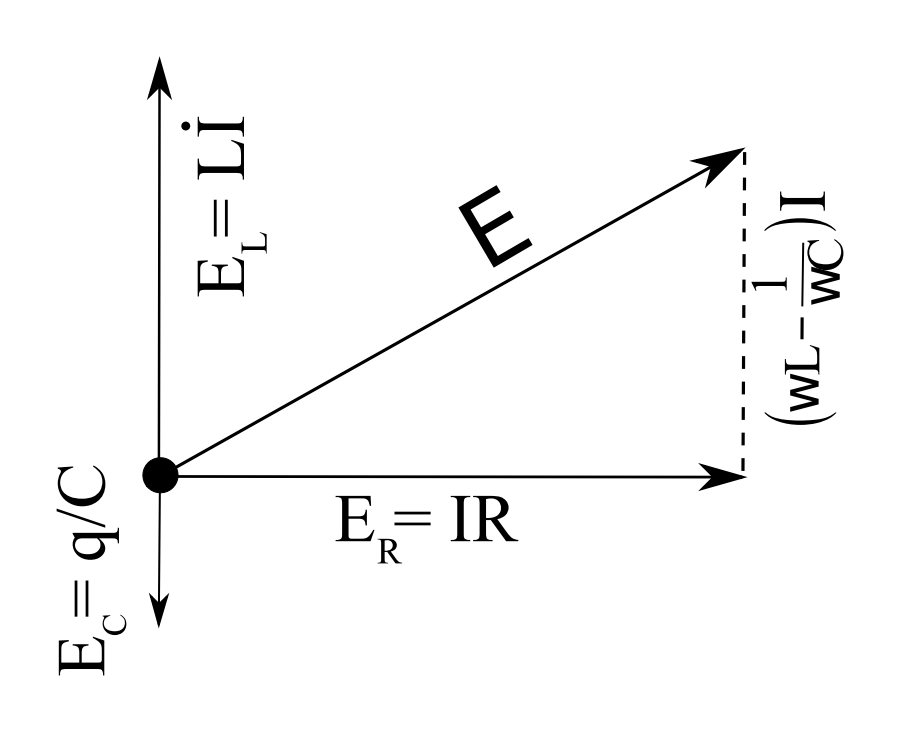

In [16]:
from IPython.display import HTML
# Original lecture figure, embedded for use without external PDF files.
display(HTML('<img src="..." alt="Original lecture figure" width="50%" />'))

Since the connection of the elements is series, the currents through the elements are the same and the impedance is the sum of the impedances of each of the elements and for the Fourier amplitudes, we obtain:

$$
{E}_{\omega } = {Z}_{\omega } {I}_{\omega }\\ {Z}_{\omega } = R+\frac{1}{i \omega  C}+i \omega  L
$$

Vector representation of complex numbers allows us to analyze phase shifts between the current and voltage of the generator in the circuit. The phase difference between the source EMF and the current is:

$$
\tan{\varphi}  = \frac{\omega  L -\frac{1}{\omega  C}}{R}
$$

That is, the current lags behind the voltage if the inductive impedance is greater than the capacitive impedance and leads if the opposite is true. From the geometry of the diagram it is clear why -π/2<φ<π/2. The amplitudes of the current and EMF are related by the ratio:

$$
\left|{I}_{\omega }\right| = \frac{\left|{E}_{\omega }\right|}{\left|{Z}_{\omega }\right|}=\frac{{E}_{0}}{\sqrt{{R}^{2}+{\left(\omega  L -\frac{1}{\omega  C}\right)}^{2}}}
$$

from which the selected case of resonance is directly  at ${\omega }_{0}=1/\sqrt{L C}$. The average power (per period) released in the circuit on the resistor is equal to:

$$
\left\langle P\right\rangle =\frac{1}{2}\left|{I}_{\omega }\right|^{2}Re {Z}_{\omega }= \frac{{E}_{0}^{2}}{2}\frac{R}{{R}^{2}+{\left(\omega  L -\frac{1}{\omega  C}\right)}^{2}}
$$

At resonance, the reactive impedance vanishes and voltage and current are in phase. The mean Joule power is $\left\langle P\right\rangle =E_0^2/\left(2R\right)$. The source prose omitted the square on the voltage amplitude.

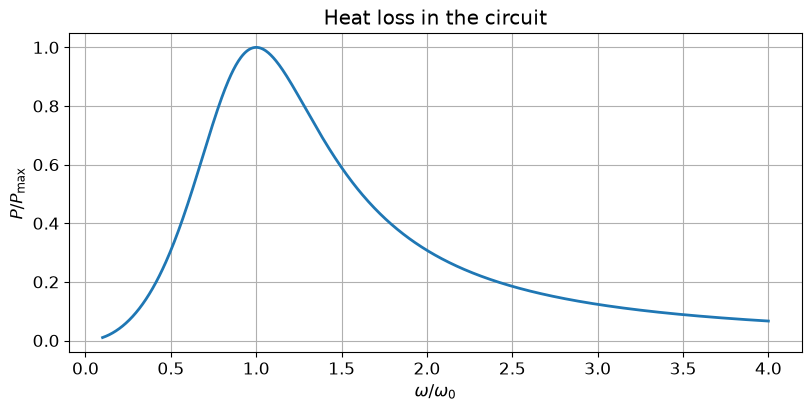

In [17]:
x=np.linspace(.1,4,800)
fig,ax=plt.subplots(figsize=(8,4),layout='constrained'); ax.plot(x,1/(1+(x-1/x)**2))
ax.set(xlabel=r'$\omega/\omega_0$',ylabel=r'$P/P_{\max}$',title='Heat loss in the circuit'); ax.grid(); plt.show()

Let’s move on to examples of problem solving.

Problem


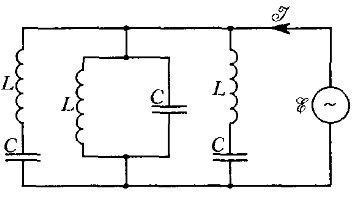

In [18]:
from IPython.display import HTML
# Original lecture figure, embedded for use without external PDF files.
display(HTML('<img src="data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAWoAAADTCAYAAACoalnqAAAk60lEQVR4nO3dB5gT1RYH8LssHaRL0ScgTXpRBBVpijSlSH0roAguXURYESsoIo8uiILsShELZUFEOoqA0gUUlyYoVXpZemfe9z86Y7I9ySQzyfx/3zekkGRvJsnJzZ17zwnTNE1TRERkW+msbgAREaWMgZqIyOYYqImIbI6BmojI5hioiYhsjoGaiPymRYsWqlSpUqpq1arJ3uajjz7iK5AKBmoi8oudO3eqr7/+WrVt21bVqVNHhYWFqfLly6vBgwfL/3fu3FmuK1euHF+BVIRxHjUR+UOGDBnUXXfdpQ4cOKAOHTqkBg4cqL7//nt18OBB+f9MmTKpAgUKyP9Tyhioich0n3zyibr//vvVgw8+KJdz586tzp49K+d//PFHVatWLVWzZk21evVq7v004NAHEZlu//796tlnn5Xz27dvV/Hx8erbb7+VywjQwCCdduxRE5FfZMyYUd24cUNOr127ZlyPIY/x48eryMhI7vk0Yo+aiPzi1KlTasaMGW5Bet26dermzZvqscce4173AHvURGSKBQsWyOnjjz+usmTJkuRtXn31VbVt2za1ePFi7nUPpPfkxkRECeXJk0dO9+7dq/Lmzaty5swpMzxefvllt9tFRERID/vq1avciR7i0AcRea1hw4Yym+PkyZMSsJE1GQcOFy1a5Ha7y5cvqw0bNqjKlSur8PBw7nEPceiDiLyC4Jw/f34JzokCS1iYcf2JEydkvjQw/b132KMmIp/mSydUt25dt8sVK1aUU8z0IO8wUBOR17p27ZpoHLpMmTJqxYoVchk5Po4fP64GDRqkevbsyT3tJQ59EJFPY9RLly6VZeCFCxd2+7+VK1dK7/rNN9808nuQdxioichrW7dulaXiruPPSMKEOdSYBTJ58mSZrke+YaAmIlN07NhRTkePHm1M2SNzMFATkWVu374tp+nS8XBZSrh3iCjgYmJiVLt27VSOHDk4rzoNuDKRiPwCBxlh3rx56vPPP1exsbFy8DGh4sWL8xVIBYc+HGj69Onq9ddfl2TuRGZCrumWLVsaC2JSs2nTJpnOly1bNr4QKeDQhw1ERUWpCRMmBCRHMFaMIU/w4cOH5XyTJk2UVbMF8Lw3btyogtmFCxfU7t273a7D8zp37lyi61KDwFaoUCF5XfQN9QZds8/ZycWLF+V56Rvai4IAeB5pCdKYJYJ51gzSFvao8aL54pdffvHqfpcuXZIP/61bt9w+HEhafs899xhHp719fH//VJw1a5b69NNP5XL//v3V8OHDVahzfS2QCyKhevXqSU/NrgHLU/Xr10/ydU3quSfcR0899ZR8yYaC1D6DKNvVr18/OT9t2jSpEoMMfZMmTVJWQG3HuLg4S/62bQM1EZGdlLMwUKcPRC6ALl26eHy/tPxUNEvZsmVVp06d5DwKb44bN07OY0XV6dOnA3awA6u3Ev5kNhMeG0fbXRUrVkw9/fTTqlmzZkaJpECaOXOmjFP6C/IfDxs2TI0cOTLR/+3YsUMVLVpUZc2aVY0ZMyZRWk5/9iRxcC2hM2fOqClTpiS6vnfv3lIo1htYbIKeqS7hfsDnLKl9k1bR0dHG0M+oUaM8uq/eWw60kf883/nz5xvlwFz3webNm9UDDzxgXH7nnXdkCbyV/N6jZrYse2natKks7cXYKoJkmzZtrG4SuWjUqJH66aefZPwXeZ1btGghq/uCCYZwjh49KpVc8OWTHHSCgmVhTFhYmKU9ah5MdBj0Ijzt+VDgoPLJ//73Pzk/derUoAvS+i8GJGJC/o8lS5aobt26JXk7/FJt0KBBwNsXjBioicgvsmfPLoEYM5rwCwELXFyhwMCyZctUq1at+AqkgoGaiPwOU/AwLo/ZWNg6d+5s/N+cOXP4CqSCgZqIAgY5PbDhoDaOX2HDEA+ljIGaiCz13HPP8RVIBQM1EZHNMVATEdkcAzURkc0xUBMR2RwDNRGRzTFQExHZHAM1EZHNMVATEdkcAzURkVMDNdbzExGRjQN1eHi4vx6aiMhROPRBROTEQI0K00Tkmy+++IK7kMwP1L///rt6+OGH1f3332/mwxI5UmxsrJSAQsUUJNkn5zItUKOc+3333afWr1+vGjduLKfYiMgzCSueVKlSRTZyLlOqkH/55ZeqY8eOUs15y5YtErCJyDsFChRwKwqN6ugffPCB1BjE5wtFb8lZfA7Uq1atklpoGTNmVJcuXTKnVURkGDNmjATusWPHqly5cqmrV6+qTJkycQ85iM9DH3Xq1DG+9YnIP9Cjfv/99+X80KFDuZsdxrQxar3EPRH5R61atbhrHSpMcx0M89Arr7yiRo4cKed9eBgKoHr16qnVq1erGzduqAwZMqjr169z/wcJrPYtWbKkOnTokLx+FDiYfVOuXDkVFxengm6Mmm+WxD9Pd+3a5fX+xE/a3Llzp3ibn376ST366KPqjTfeUEOGDFHdunWT6ydOnGicT86FCxfU999/7/b6FSlSRDVq1EhZpUOHDqpGjRrG5WPHjqlBgwbJkNrKlStV9+7dZfZQ165dldNhtS8Cxs2bN61uCgVTj/rPP/+UI9Hg9B710aNH1V133WV1M0LW5cuXVZYsWZTT4fOGz53TP2+BFtQ96hw5cpjXkhCyd+9er+6HnjJ6lIG2efNmmfK1bds21aJFC+mZR0VFGf+PHlzp0qW9fl4pGTBggCzsICI/Bep8+fIZ57/77jsZ/3Q6/JTXf2V40yv3J6xuq1Spkjp48KDbMmV9JSnanVxPzV89uNmzZ6f4/02bNlXffvutX/52sMHrdvbsWVW7dm2rm0LBNutD/7nPXpH9YQ7ugQMHJOjq2zPPPGN1syiNcBARgVqfEkvO4XOg3r17typatKj65JNPVLNmzcxpFRG5GTFihHGwuFOnTtw7DuNzoM6ePbvat2+fnJ8/f75jF75Mnz5dTuvWrWt1U0LGtWvX5BfAvffe69j85ugAYcPwzyOPPKJOnDihChcubHWzHPnZbt26dXDO+nCF+dSYV208cFiYzNFNn96UdCK2h+cLPBpvnnPnzslwTcuWLR01tIZpk0jJ4Co6Olq98MILlrXJyQoVKiQH+a38bJu2MjHhATQ8qRkzZpj18ESOMWnSpETXMUg7mymBesWKFTKtC4likDtXP1DVvn17Mx6eyFF69uwps12wVa1aVa7Dwh9yrvRmVHN54okn5DzGzzi3msh333zzjTEMgsU+GAL6448/1LJly7h7HcjnHjXm4N6+fVutWbOGQZrIZMjHgsVIH374oVq+fLnM0yfn8SlQ44i8Dkekicg/evXqJaeff/45d7EDpfM1oTk4feUYK9pQIKCSEqB3Tc7iU6DeuHGjnGKeq1MP+mBaHor6EvmbPn/69OnT3Nk2mY0TFIF63bp1yqkwXerjjz9WBQsWdFuSTebDwTQcB6F/55dT4I0bN04F/TxqJ8FS+U8//VSVKFHCLxnlyN3ixYtllSL9Dfk+yFl8CtQvvfSSnM6ZM0c5BZ4zlsqPHj1a7dmzR2XLls3qJoU8rExkLmqlFixYIPsDuXXIWXxeQu60pdNOe752WEIOLBzA957VS8itLByQzuwj0kRkvpiYGO5WB0sUqHGADHOi0XPUt4ceeijZB0DPsmzZsqpdu3Zu9fhCUUREhJw+/vjjVjeFHGTp0qUqMjJSfl0cOXLE6uaQHZaQ9+jRQz3wwANGcD516lSqKw6xKhFFWbGUHKehPn2IyaYCq0mTJipz5szKifLmzavOnDkj5/fv3y+rFMkaKCxtlXRpeaNgGWtK8E2POdXoXeNNpffEuYqKzIAFVVevXnVUQNA/Q3qQ/vXXXxmkLYa84LYM1G+88UaaH+izzz4zzlepUkU29K5DiX60/c4777S6KRTC/vrrL/n8uPae165da2mbSBkFBCyhJaFo0aKY0qC98cYbWlo0adJEbn/nnXdqcXFxWijD80xmt5HJ4uPjjf19+fJlx+3fAwcOaGPGjJHnX7BgQaub41gFCxaU16BcuXKWtSHJHjXGwuC9995LNdBj2sqGDRtU9erVJc0pprCE+pxeeOqpp6xuimME8zxq14Py+ubJkvE+ffrIkGKBAgXkF92wYcP82l6yqYSRu0ePHmnuNbr2eJykbNmyxjfs9evXrW5OyAqFHjXeHxUqVJDnkDt3brmua9euXj2Wvi/Onz9vcisp6HrUWHUHU6ZMSTXIDxw4UDnR9u3bpaINTmvWrCn17IiSgoRdv/32m5yfO3eunE6cONGnnTVq1CjubIdJFKgPHz7scX5pq1brWAnL5jH8gWGfLl26yE/a/v37W90ssrE6deqYMj0MM0DIwYFany9drVo1VapUKavaFBTwS1TPvaCrX7++Ze0JRXg/Yg51MPNHqoF58+aZ/pgUYjUTkbQcmcyioqKUk2E1Jrz//vuqQYMGUpKMzHX+/PmgL0pRoUIFtwRmFDza/1OcOz4+3hht0K8L9BoRI1BjxsatW7fkPH7OJ2XhwoWqd+/eHs2vDjUnT56U9KYIIt26dVOvvfaa1U0im3ItKGFmFaBixYqZ9lj0t3379kk2zAEDBkjB7uSShH3xxRdyXj+FRYsWqYoVK6q7775b+T1QowgAMpQlB9ODEMyTmrZXq1atkF82rtu0aZME6XfeeUe9/fbbVjeHbGzy5MnG+e7du5v2uCxwa67atWurzZs3q0uXLiUqFNCmTZsk74OCIbrGjRurO+64Q9WrV884YGy2sGvXrmFhi8qYMaORUjIpWCIeGxsryZdcu/1OS/upP18E7KpVq1rdnKDzyiuvyIHYTJkyycHYESNGpHj7pk2byvBHMKY5Re8M857xK3Ts2LGmvfdwULFGjRomtNDZ5s+fLzFNX3E4fPhw4z2aVjt37pRjVbNmzVI///yzXPfdd9+Zn7jN1/l9P//8s8wxfP755zUncOK8cTPs3r1b9hvmFK9evdq4fu7cucY+PXbsWLKrXoNxHvWrr74qbcdnxFeHDh2SxypVqpQpbXO6uLg42Z+ZM2eW96QZNmzYYMyZx+ruS5cuaWbxOeKgMcWKFZPG1atXTwtl+gePgdoze/bs0bJkyZLsfouOjpb/e++990IqUOfPn9+0QJ03b16tUqVK2tWrV01pm5NVqlRJCw8Pl9dm165dpj9+p06d5LE3btxo2mP6XDgga9as6o8//lB9+/aVLj9+nmFCPrYdO3aoUHLgwAGrmxB0Vq9erUqWLKmuXLmS7LQyzC/Onj27CiVY1IJjOpgdhLTByeWZxuclqfeV/hl67rnn5DaVK1dWv/zyiwwZkfcwTIF56Fj7sHLlSlMP8upQTxXxEFNLTcvR749hAX2bPn26FkoiIyPZo/ZQr169ZJ9t3rw5xdtVrFgxJHrU586d006cOKEVKFBA2n3ffffJMnJcp2+A03bt2mm1atVK9BgxMTGJPksTJkyw4NmEliNHjsi+bNu2bUD+HkYY8PdOnjzp82OZFqhnzJhhvKkWL14s219//aWFGg59eL6/ihQpInk7UrN3796gD9TPPvusW4AtXLiwW84SbA0aNNDCwsLkfFKBGvTPkH4f5Jeh4Pvsdu/eXUufPr22du1anx7HlFYvWLBAdgAaFeoWLlwoz3X06NFWN8URyWyCLVCnRUREhLGlRceOHWUfLF261O9tC1WRkZHy5bhmzZqA/t0lS5bIa9e3b1+fHse0WR/9+/fXnEAP1HjRKXnLly83ejA3b970eleFYqD2RpcuXWQ/pEuXzuqmBCWllBxAtOpvY2vTpo11BxP1ucTBnCcX81xd8wVjWTgmwCcFk9uxKgn7H2XK9CRWlDw9IyP5VgYKq2Bv377tyN24d+9e9fzzz8vmyTxnqFu3rpzevHlTWQFl5HAwGCu+r1+/7t2DmDE3tlq1alqwy5EjhzyXBx98ME23Hz9+vPFNiYMT33//vWyUuEfNoQ9z/PTTT7I/Bw4c6Ki32a5du+TzefjwYblct25dLWfOnNrOnTvlM4dxfkxfxFjwwYMH3e6Ly3aokPP6669LOxYtWuTV/X0K1C+99JL88WAvv4WxP/3gTlKLLpLjerCHBxndMVCbD3OocWD2jjvu0JyiZMmS2gcffKAdP37c7Xpczpo1q5YpUyZZDISZFQjkY8eOdbudPvvGDgvy9Bjx+eefe3xfj7PnhSL8NMF+xJJm5DRJ63xMPQUncp00bNjQz60MLsh7gHwIKNV2/PhxKdiaXNKaP//8U+XJkyfFFAakZA51eHi4unDhgmN2x5EjRyS9Rf78+Y3rUJkdc9NR9q9Vq1bqP//5jyzlRkFgPWe3Du+9hHlXrBIREaG++uqrRDlF0oKBWil16NAhj/JJIysagjQ+OKjegQUdlNjRo0dlHP/UqVNq/fr1Rr3JhB/E4sWLy4ZxSCJXWJBy7Ngxt+vwntI/txizR5BGxSUsMNJz6gOONdnJ008/LYHaGz4fTAwFvXr18uj2evUbHHBkkE7ZCy+8IKfo+eDAM7Y1a9bIqjycR3pI5PIOtVWsZA58xrZv3y4HERPC+wefRfRQEaxdg7SrCRMm2OLlQKImdO6GDBni+Z3NGncJ9ul2aX0OnEftOSx8evHFF93G8nEZ27p161K8L6fn/cupBxNnzJihtWrVSuvQoYNWvXr1NB8TGjJkiNxmxYoVHv09jHMnPPbkmq9ly5YtxmN7CkmgvLmfzxE2e/bs8ofNzBQVSC1btpT24yiyE76YrHTlyhU59aSKNgN14vfe0KFDNSeKj4/XBg0apOXKlUu21HgTqPVl3/rj4776RANsK1euNNZReLMAydtA7fMYNRKb6D9hg22MESXF8DMcmHDJP3CA1vWgIaqTILc56nLqJaqeeOIJ1bFjR9WoUSPVtm1b9fLLL0u1DT3vN2AM8sknn1RLlizxqh133nmnmjJligpWH330kZxOmjRJRUZGKqfZuXOnxJl+/frJeQyp4b2VIUMG9fXXX5v6tzDvesWKFcZ5DNMhyRaKAiCBWLNmzaQQREBrpGomwUPlzp1bmzlzphYssNoN7S5UqFCafxGwR+1dEiurN+TcCFaxsbHyHFq3bq0dPXpUc5qf/1n93KhRI7msv6YTJ07UWrRooc2aNcvUoQ9/8rZHbdrBxMGDB6uzZ89KjwgD5ti+/PJLZWc5c+aUU3xTI11rcpha0jvo/WHqY0qbGVBwWYdKGzj6n/DvuNYvDAYo96Z/jnAgFs8Rz821BJRTxMTEqOrVq0vNVv1AHFIqd+3a1a12YSgzLVC/+eabxnksk8Rm9+WuN27cSPU2+KnDklve04NNcts/x0l82jBrRz/funVrGeZI6m8FE3Qi9M8RpE/v3Jm0EydONNI7YPgBU9z0Ulcp1aLEUBo89thjyg5QqistMScppr36+HaDChUqSK/azpXKkYDdte4jCvMiwX1SRS/BdWoQJtljuhByfGCiPZE/1KxZU04xBx1jsghIDz30kOSMcKKPP/5YTrds2aL++9//GvP0MZcaX85JwQIYu1U6v3XrluRt8ZgZ4y76kVKUHgqGLGc1atRwG7/ct2+fbAmvw9g1Tl0Tf3N6HgXSxYsXjfcmlkvv37/fcS+AUkrLmDGjsR90PXv2TNN9sUVFRWlWw1g62vLJJ594fF+fe9Q4+orxokcffVT9+OOPKhgkXGaqS1hJHavmEsICF4xno9QOfk736NHDb+0MBW+99VaqxzYA1ciRFe3kyZMyGwe/WNCDdPXNN98YlZ4hd+7c8jpgFgkqlac2lBAVFaWCTbZs2WRDygLMcihatKiUd7LLz/lAWLhwoZRxu/fee433FIaCxo8fn+p9Dx48qAoXLiy/mq3Wpk0bOfVqKNXXbwmnzoLAvGs8bxRNMKPUTqiyerZHKMz6cPqCF1fexJo6depYHqP09QAoBO4Nn3rUY8aMUU6Fce5Vq1ZJL6dQoULyrQ3IaUH/WrduXYq74+GHHzZ9d+EXHpJCwcyZM+WYSajNghg0aJByokgv5pBjDjqOLdWoUcNYNxFISKKljzbExcV59yC+fEuESppTb2EpacKeG5mLKxPdoUfG95nmda/ainSnI0aMkL+NZfDeYlImL2FuLpIJZcmSRaYm6tPDiMh+fvjhBzkN9OpUzH/HsZfMmTOr2bNne/04DNReKl++vBzcQApG/YAYEdnX7H8C5bvvvhuwvxkdHW0MwfnCp0CN/B6wfPly5RQIzEiniJkfyF2RXGpFIrNh5gJSepYuXZo71wtY4Tlq1Cg1cOBANXXqVCOfjNmwzmLcuHGyQAf56tu1a6eaNm3q24P6Ov7itLFZzqMOLI5R/4uzPswxZ84cY262P2TIkMGIi127djXlMX0e+hgwYICcmp3Byq70uZtOmsdK9jBy5EirmxASWrRoIaW5sDw/X758KS5D98Tu3bvlsbBMHCspsWH5uynMiPYRERHy7bFp0yYt1DntF4TV2KP+W/PmzeV9V7lyZYtfkdBSoUIF4zO9du1a2TyBNRS4z5NPPmk8ztSpU01vpym5PpAlD4VLsZIMK6eCLS81kZ0hfw7m32KWEefpmwv5znGsDdkV9RJ7qN+pr5ZFncOklChRwpgjjWyNgAx/yCGk/5+ZwhCtTXuwsLBE14XalDX9OYba87IrHITB8vDLly/LVEinBA8UVkDyoRkzZsh1jRs3lqXU5L+0EsuWLZPznsziwkIaDKU0b95cvkj9xdTciQheOMKp56HG+E8o0b85KTCQJhcBGjNskuoEhKrFixfLKaqM4BcqMEj7F3IVYXOdvoc8Mohlx48fl8uoJoORAz0TXkCZPpiiadrrr78uYzXTp0/XQsnOnTs5Rh3gGnl4H6GupZPgOWfNmpU5ZGzgzJkzWp48eRIVuA00vyx4KVWqlNtqoFCB+asNGjSQ89u2bbO6ORTCwsPDQ+4XaTDKnTu3ypgxo5x/4IEHLGuHX1cmYgpMqOnTp4+kN61UqZKk4yQi8jcuIfdQw4YNjVp/qF+XXHUJIqKgCNTTp09XoQpr+OPj41VsbKxRzw3pNYmIzMYetQ+VbYiIAoGB2ksoMoqpOki+oqc41ZPVExGZybk16L2E4Q7MbT137hwXvRBRQLBH7UUeagRpPRkVEZG/MVB76K+//pLToUOH+uP1ICIKbKC2Q4l2M0VERMjpyZMnrW4KETlIOn8vDiEiIt9w6IOIKFQCNTKZ3bx5U7Zbt26leFsnZTojSgmmbeIzg89E+vTpZUP6Uv2zRGRqoEZRAKT5w3bPPffIeK0+ZpuQnpox1PTq1UtOu3TpYnVTKAh89dVX6sknn5TPDNJl6sF52LBhKnPmzHI9kc+BGpVa9OXRzzzzjLGw48iRI/KGQ1LzpDJKBTxXa4DUqFHDUfUhyXvIJY3PzI8//ijVQ1w7NUWKFGFvmswL1ChRA998802iA4OzZ892dM9ywoQJVjeBbGr16tXGKtWDBw+qkiVLWt0kCtVAjZzSV65cUZMmTZJySEnBWFtSqlatqkIVflF89NFHqkePHmrUqFFWN4dsSE8rgLn2yGecnM6dOwe0XeSb4cOHK1sF6s8++0zt2bNHFShQQEVGRiZ757p166r77rsv0fVI/xnKEKRR+DIqKkqGhbZu3Wps5GwHDhxQc+bMkfP58+dP8bYxMTEBahWZAXHRVrk+nnvuuTRniNPrI7pasGCBCnUI0oULF1Zt27Z1K2rJorfO9vbbbxvnO3XqZGlbyFxz585VtgnUy5cvN87rxR49hcq8TtCmTRt16NAhNX/+fBmXJIqLi+NOCFGl/ikxaIuhj3nz5rlVM/GGUwI19OvXT61atcrqZpBNbNmyxeomUAjyy8rEWbNm+eNhiYJqDjWRrQO1PsZN5FTJLQYjMj1Qv/nmm149KJFTPfvss2m6XcaMGTnrg7wP1JgjnBbdu3dnTg+iBFyns7rOBnJVq1YtdePGDVW7dm3uP/K+R71jxw6VNWtWNWTIEJkFcvbsWeP/tm3bpt577z21c+dOY74oEf07UwoHFNFjxrx6zLNH5wefI3xecLl+/foyjZMrFsmnedRlypSRfB1Y8II3VZ48eeSNp9cMRM4L5DJIl45ZUokSqlKliiwdHzx4sARpPZlXrly5JE9OoUKFuNPInOK2WFWFb33XZZMIzFjoQUQpQydn/PjxslHo1EuNs2iefPrkVhu2a9dOki61bNlSNWjQwPi/V155xTj/22+/qQoVKpiemxqPq8ubNy97IBQ0Dh8+LGmAk4MeNsaoE/rwww8lr47uwoULxmdnw4YNMhSpS+0zp8NCrCZNmnj4DMiWtCTgartsvXv31oKB3l67e/7557XKlSvLtnTpUs3O4uPjZZ/mzJlTu3LlihYM9u/fb/lnRt/mzp1r9e4ICQULFpT9uWPHDsvakGSPev/+/Wrs2LHG5Z49e0pBVyxk6dChg4zBuUIi9FdffVUNGjRItpSMHDlSlmLqGfk2b94sj+c63t23b1/jfM2aNVUwQeZA5CH2lOtzTsru3btV8eLFpUKIbvTo0W73Q6/sxRdfNM5j32EIK0uWLHLwV8+nrcMvpbJly1qWxe2ll15S4eHhSf6iO3bsmGRvhHPnzgVNDhXkmk6prdHR0fJamAkFCHBcCQf6Xd8bZC7sY6uEIVpb9tdDCMuP+dfly5flC4co0HDwFx0HpMaw1Rg1eW7RokU+7bbGjRtb3n5UIkGBCKwsRVbAAQMGSI/ctdeOHOTnz5/3+fkCxk9Tq78J+CWgzzoiciL2qB0Ew1cY6jh16pRcfuSRR1Tz5s3dDhCT+Tk/MMS0dOlSLisPUoVs0KNOMlDjKHPC8cxAYnVm/+5bvajqzJkzJVUrmcv1OAJ+MeD4y+3bt2U8HjMxXCsmYQYI1iTo8OW5cePGJGeLYHqYJ6sZt2/fnmRhDwqRoQ9UHLfLeG/v3r3dDmySeUGEzIe85AmHcxCkAdejKrmrH374IU3HN7p16+ZxW0qXLh00B2EpZemT+ybGTA/9jeQp/MzTc1ljgQzKVnkCJb50JUqU8PjvU8owX9fJhYn9CT3klIIjxv3xizUhVIOZPHmynF+5cqWcogedL18+4za4fObMGVndqHvqqadkefqSJUuMy5jFg7qN06ZNM/W5UQiOUeu9BH6j2w8KriIVAIc+7En/7Hz99ddyDIGsZYehDybrcCAEabI3zHKxsvQTJZZSoW9/Y6AmsqFMmTLJDB2yDyxWsgoDNRGRzTFQO5DrwVoisj8Gagdq1qyZ1U2gVCB73sKFC7mfSDBQO9CePXusbgKlYb47UvwSAQO1A6FeH9kX5lRjBSmmhBEBA7UDuSaoJ/vRF76QPfz5559WN4GB2okYqO0vc+bMqnLlylY3g5SyRXpd9qiJbOjq1avql19+sboZpP5OUmc1BmoHeu2116xuAlHQaG6DZfwM1A6EVJpkXygicccdd9giQJA9MFA7ECtT25vV1X7IXdGiRZXVGKiJbFojErmtyXquqWatwkBNZEOownPPPfdY3QxSSn377beW7wcGaiKbzvr49ddfrW4Gqb/zUVuNgZqIyOYYqImIUnD06FHL9w8DNRGRzTFQExHZHAO1g1y7dk2tX7/eqEDOdKf2g+Kp+/btk/O7d+9Wv//+u9VNIjvQ/AQP7ceHDzq7du3SSpQoIecffPBBrVOnTlqfPn3kcv/+/QPShn379hmvi75FRkaa/neioqLkuR4/ftztelxXtWpVzY7Qtj179qR6u+joaLfzuJ8n24oVK1J8/GrVqrm9PtmyZdMuXbqk2cGkSZPcLp8+fdrtucXGxmrt27eX/xsxYoRx/bvvvqvZQYkSJbT58+enert+/fq5vY+x4bUoV66cZpUw/GN28J82bZrq2LGjV/eNiopSOXLkSPE28+bNU1u2bFF9+/aVxDUrVqyQ66tVq6Y2btyoIiIiVJkyZdTgwYPVW2+9JUUpL168qM6ePaveffddFRMTow4ePKjsCO17++23lVNUqVJFbd261epmEKXKD6EyzfwSqGNjYyXgeuPw4cPq1q1bprUlT5486syZM26VM+6++2514MABVaRIEWUHp06dUpcuXfLpMbJnzy4VQU6cOKHy588v150+fVpdv35d3b59WxLRJ5fCUb89hkbSpUsniy38Dc8Xz9sTeL3wutn5tUwJ3td4f2OlW9asWVVYWJjxf/Hx8ercuXNJ3g8LX/C6BCvX1ywt8HwPHTpku+e+f//+0ArUvsAYKoKLWUqUKKH27t3rlucXPW8sz61Vq5ayA4xFHj9+3OdJ+SVLllTbt29X5cqVM8ag8UsCFV2wgKJ27dqJ7vfbb7+p8uXLG3X6wsPDJYj4G75Qdu3a5dF98Hq5Lqu242uZErwO69atU6VLl5Zg7RqAEATWrFmj2rdv73afVatWqRo1asjrEqw8XQqPpGFr166V88H+3EM2UJN/DRs2TL640BudMGECd7cNRUZGymmPHj1kaIiIgZqIyObsMfhDRETJYqAmIrI5BmoiIptjoCYisjkGaiIim2OgJiKyOQZqIiKbY6AmIrI5BmoiIptjoCYisjkGaiIim2OgJiKyOQZqIiKbY6AmIrI5BmoiIptjoCYisjkGaiIim2OgJiKyOQZqIiKbY6AmIrI5BmoiImVv/wflIBQ/CqxPdwAAAABJRU5ErkJggg==" alt="Original lecture figure" width="50%" />'))

Find EMF frequencies which provide current and voltage resonance conditions. Inner resistance of EMF source can be neglected.

Solution

It can be immediately noted that since there is no active resistance in the circuits, the current phase in relation to the EMF can only take values ​​±π/2. Resonance in this case occurs at ${Z}_{\omega }=0$. Let’s find the impedance of the circuit, which consists of three parallel subcircuits, two of which are identical:

$$
\frac{1}{{Z}_{\omega }}=\frac{1}{i \omega  L}+i \omega  C+\frac{2}{\frac{1}{i \omega  C}+i \omega  L}=\frac{1}{i}\frac{2{\omega }^{2}L C-{\left({\omega }^{2}L C-1\right)}^{2}}{\omega  L \left({\omega }^{2}L C-1\right)}\\ {Z}_{\omega } =i \frac{\omega  L \left({\omega }^{2}L C-1\right)}{2{\omega }^{2}L C-{\left({\omega }^{2}L C-1\right)}^{2}}
$$

Next, one need to analyze the multiplier for sign alternation.

Problem

When the coil is serially connected to the electric heater with resistance R,  its power becomes twice as low. Find the coil inductance L if the frequency of EMF is ω.

Solution

According to the condition, we have a series RL circuit with impedance Z = R + i ω L. The released power is equal to:

$$
\left\langle P\right\rangle =\frac{{E}_{0}^{2}}{2R}\frac{1}{1+\frac{{\omega }^{2}{L}^{2}}{{R}^{2}}}\Rightarrow \frac{{\omega }^{2}{L}^{2}}{{R}^{2}}=1
$$

the answer is straightforward

Problem



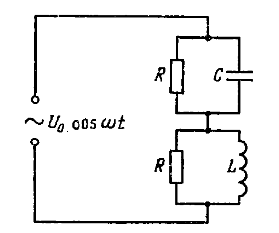


Find the relation between parameters of the circuit at which the current amplitude depends on the voltage amplitude only (but not on frequency). Find phase difference between source voltage and the voltage of RC-subcircuit.

Solution

If the total current amplitude is independent of frequency, the magnitude of the equivalent impedance must also be independent of frequency. Calculate the impedance:

$$
{Z}_{\omega }={Z}_{RC}+{Z}_{RL}=\frac{{Z}_{R}{Z}_{C}}{{Z}_{R}+{Z}_{C}}+\frac{{Z}_{R}{Z}_{L}}{{Z}_{R}+{Z}_{L}}=\frac{R}{1+i \omega  R C}+\frac{i \omega  R L}{R+i \omega   L}\\ \left|{Z}_{\omega }\right|^{2}=2R\left(\frac{{L}^{2} {\omega }^{2}}{{R}^{2}+{L}^{2} {\omega }^{2}}+\frac{1}{1+{C}^{2} {R}^{2} {\omega }^{2}}\right)
$$

From here we obtain the condition $L=C {R}^{2}$. Finding phase shift is straightforward.

Problem

Determine the potential difference between points A B on the diagram with harmonic EMF


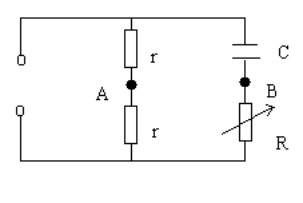



Solution

According to Kirchhoff’s laws we obtain

$$
{U}_{C}+{U}_{R}=2{U}_{r}, {U}_{AB}+{U}_{r}={U}_{C}\Rightarrow {U}_{r}=\frac{{U}_{C}+{U}_{R}}{2}, {U}_{AB}=\frac{{U}_{C}-{U}_{R}}{2}
$$

The capacitor and resistor voltage phasors are orthogonal, giving $\left|U_{AB}\right|=\left|U_r\right|$.


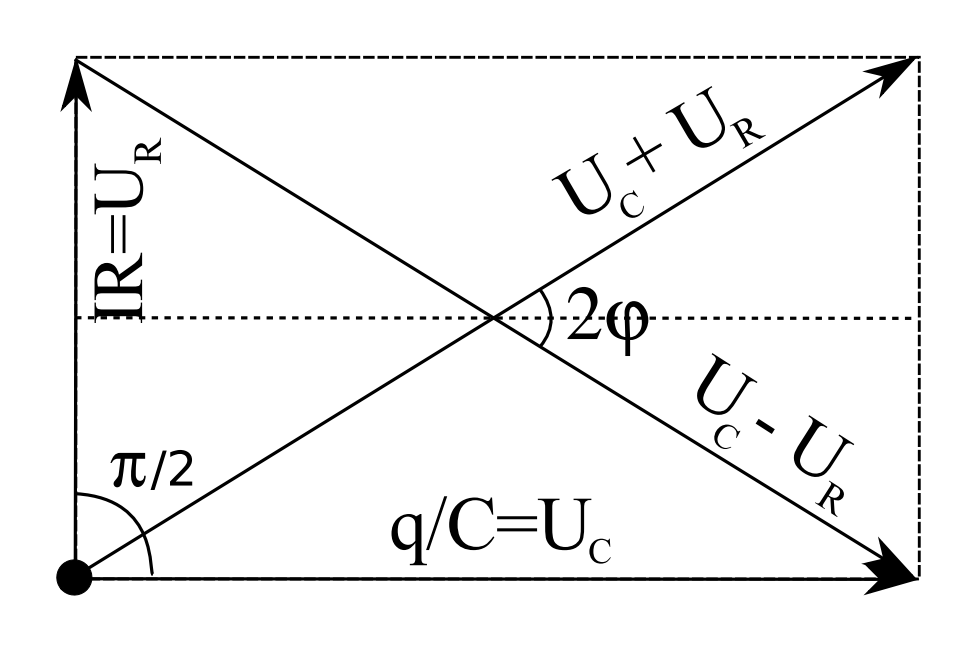

In [19]:
from IPython.display import HTML
# Original lecture figure, embedded for use without external PDF files.
display(HTML('<img src="..." alt="Original lecture figure" width="50%" />'))

$$
{U}_{r}\left(\omega \right)=\frac{E}{2}, {U}_{C}\left(\omega \right)=\frac{E}{1+i \omega  R C}\\ {U}_{AB}\left(\omega \right)=\frac{E}{2}\frac{1-i \omega  R C}{1+i \omega  R C}\Rightarrow {V}_{AB}=Re {U}_{AB}\left(\omega \right)=\frac{E}{2}\frac{1-{\left(\omega  R C\right)}^{2}}{1+ {\left(\omega  R C\right)}^{2}}
$$

## Exercises

Problem



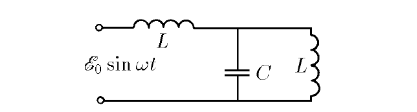


Find current in the circuit

Problem



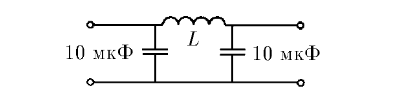


Find coil inductance L at which in and out voltages differ n times. Generalize the solution assuming different capacitors.

__Problem__


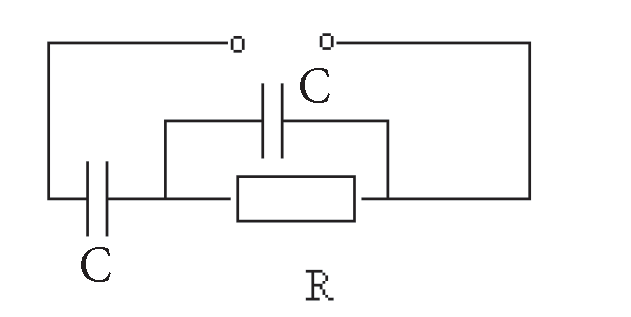

Determine the power of heat losses in the harmonic EMF circuit assuming that ω R C>>1. Solve the problem using the impedance method without this simplifying assumption.

[Back to the course contents](https://colab.research.google.com/github/kulinskij-tech/ClassMech/blob/main/ClassMech_Python/classmech_TOC.ipynb)